# The Wood backend: the mathematics, and the workflow

`magli` ships two GAM engines. This notebook is about the default one,
`backend='wood'`: a pure-Python implementation of Simon Wood's GAM framework
(Wood 2006, 2011, 2013, 2017) — the same machinery that powers R's `mgcv`.

It has two halves:

* **Parts I–VI — the mathematics.** How a smooth becomes a design matrix `X` and a
  penalty `S`, where the penalty comes from, how the sum-to-zero constraint is
  absorbed, how `lambda` is *optimised* by REML/GCV instead of grid-searched, and
  how the standard errors, the effective degrees of freedom and the approximate
  F-tests are computed.
* **Part VII — the workflow.** A five-step recipe on an engineering dataset:
  fit, read the summary, compare models, check the diagnostics, and report.

**How to read this notebook.** Every formula is followed by code that checks it.
Cells marked *Check* end in `assert` statements — if the notebook runs top to
bottom without an error, the mathematics in the markdown matched the library
numerically. That is the whole point: you are not asked to believe the equations,
you are asked to run them.

Prerequisites: linear algebra (matrices, eigenvalues, Cholesky), basic statistics
(least squares, Gaussian likelihood), and a passing familiarity with GAMs.

Companion material: the derivation-heavy chapter `docs/math/wood.rst` in the
repository, and the R package `mgcv` documentation for Wood's original wording.

## 0. Setup

We import the public API (`GAM`/`LinGAM` for a single smooth, `GAMCore` for a
formula), the low-level helpers of the Wood backend, and matplotlib.

The low-level helpers are the interesting part for this notebook:

| import | what it does |
|---|---|
| `build_smooth_basis` | builds `X` (design) and `S` (penalty) for any basis code |
| `rescale_penalty` | the `S.scale` normalisation (Part III) |
| `absorb_sum_to_zero_constraint` | the QR absorption of the identifiability constraint (Part III) |
| `fit_wood_engine` | the solver: given `X`, `y`, `S`, it estimates `lambda` and returns everything |

In [1]:
%matplotlib inline

import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

import magli
from magli import GAM, LinGAM, GAMCore
from magli.wood import (
    absorb_sum_to_zero_constraint,
    build_smooth_basis,
    fit_wood_engine,
    rescale_penalty,
)
from magli.wood._smooths import _eta_1d

np.set_printoptions(precision=4, suppress=True)
np.random.seed(0)

print("magli", magli.__version__)
print("backends:", magli.eilers.__name__, "+", magli.wood.__name__)
print("numpy", np.__version__)

magli 1.0.0
backends: magli.eilers + magli.wood
numpy 2.5.2


---
# Part I. The model, and why it needs a penalty

A Gaussian additive model says

$$y_i = \beta_0 + \sum_{j=1}^{J} f_j(\mathbf{x}_i) + \varepsilon_i,
\qquad \varepsilon_i \sim N(0, \sigma^2).$$

If each $f_j$ is allowed to be *any* smooth function, the minimiser of the
residual sum of squares is nothing like unique: infinitely many curves
interpolate the data exactly. Something has to say "prefer the boring one".

That something is a **penalty on wiggliness**. Write each $f_j$ in a basis,

$$f_j(x) = \sum_{m=1}^{k_j} \beta_{jm}\, b_{jm}(x)
\quad\Longrightarrow\quad
\mathbf{f}_j = X_j \boldsymbol{\beta}_j,$$

and charge a quadratic price for wiggliness,

$$S_j(\boldsymbol{\beta}_j) = \boldsymbol{\beta}_j^\top S_j\, \boldsymbol{\beta}_j .$$

Fitting then means minimising the *penalised* objective

$$\mathcal{L}(\boldsymbol{\beta}) =
\|\mathbf{y} - X\boldsymbol{\beta}\|^2
+ \sum_j \lambda_j\, \boldsymbol{\beta}_j^\top S_j \boldsymbol{\beta}_j,$$

and the one knob you must choose is the vector of smoothing parameters
$\boldsymbol{\lambda} = (\lambda_1,\dots,\lambda_J)$.

The payoff of the penalty is that the fitted model now has a *fractional* number
of parameters — the **effective degrees of freedom**,

$$\mathrm{EDF} = \operatorname{tr}\!\big[(X^\top X + S_\lambda)^{-1} X^\top X\big],$$

which slides continuously between $\approx 1$ (a straight line) and $k$ (a wiggly
interpolant). Everything in this notebook is a consequence of those two formulas.

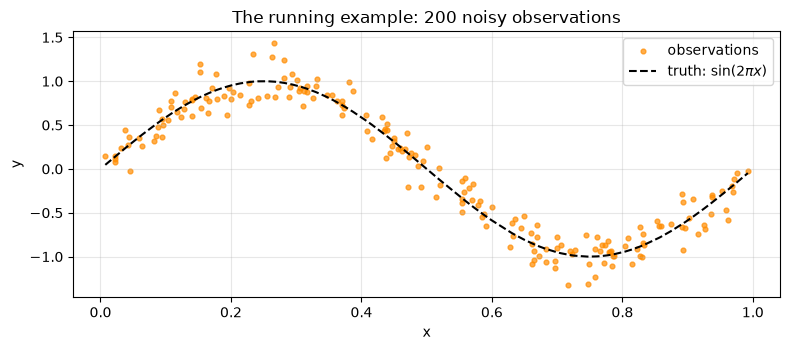

noise level: sigma = 0.15 -> expected RSS at the truth = 4.5


In [2]:
# A one-dimensional problem we will reuse through Parts I-VI:
#   y = sin(2 pi x) + noise,  x in [0, 1]
rng = np.random.default_rng(42)
n = 200
x = np.sort(rng.uniform(0.0, 1.0, n))
f_true = np.sin(2 * np.pi * x)
y = f_true + rng.normal(0.0, 0.15, n)

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.scatter(x, y, s=12, color="darkorange", alpha=0.7, label="observations")
ax.plot(x, f_true, "k--", lw=1.5, label=r"truth: $\sin(2\pi x)$")
ax.set(xlabel="x", ylabel="y", title="The running example: 200 noisy observations")
ax.legend(loc="upper right")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("noise level: sigma = 0.15 -> expected RSS at the truth =",
      round(n * 0.15**2, 2))

### The smoothing parameter as a dial

Before fitting anything, hold $\lambda$ fixed and turn the dial by hand. The
Wood backend lets us do exactly that with `sp=` (an alias of `lam=`), which pins
$\boldsymbol{\lambda}$ instead of estimating it.

Watch two things at once: the shape of the fitted curve, and the EDF. As
$\lambda \to 0$ the penalty disappears, the curve chases every observation, and
EDF climbs to the total number of coefficients (8 smooth coefficients + 1
intercept = 9). As $\lambda \to \infty$ only the *unpenalised* part of the basis
survives — for a cubic regression spline that is the two-dimensional space of
straight lines, of which the constant direction was already absorbed by the
constraint in Part III. So the model floors out at EDF = 2: **one parameter for
the straight-line trend of the smooth, one for the intercept**. The smooth's own
EDF floors at 1, which is why a term's EDF is never smaller than 1 unless you use
one of the shrinkage bases. (The table below stops at $\lambda = 10^4$, where the
EDF has already fallen to about 2.3; $\lambda = 10^8$ would sit exactly on the
floor of 2.0.)

    lambda      EDF       RSS
     1e-02   8.9960    4.4863
     1e-01   8.9602    4.4863
     1e+00   8.6462    4.4883
     1e+01   7.1733    4.5337
     1e+02   4.9464    5.6469
     1e+04   2.3241   35.6943

At lambda = 1e8 the model EDF reaches its floor of exactly 2.0


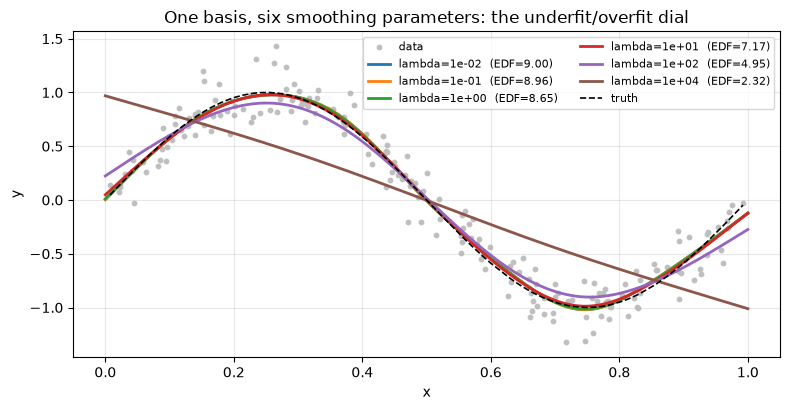

In [3]:
lambdas = [1e-2, 1e-1, 1e0, 1e1, 1e2, 1e4]
x_grid = np.linspace(0, 1, 400)

rows, curves = [], []
for lam in lambdas:
    m = LinGAM(k=9, bs="cr", backend="wood", sp=lam).fit(x, y)
    rows.append((lam, m.statistics_["edof"], m.statistics_["rss"]))
    curves.append(m.predict(x_grid))

print(f"{'lambda':>10} {'EDF':>8} {'RSS':>9}")
for lam, edf, rss in rows:
    print(f"{lam:10.0e} {edf:8.4f} {rss:9.4f}")

# Check: EDF is squeezed between saturation (all coefficients) and the linear fit
edfs = [r[1] for r in rows]
assert edfs[0] > edfs[-1], "EDF must shrink as lambda grows"
assert edfs[0] > 8.9, "with almost no penalty the smooth uses all 9 coefficients"
assert 2.0 < edfs[-1] < 3.0, "with a large penalty only the intercept and the straight line are left"
print("\nAt lambda = 1e8 the model EDF reaches its floor of exactly 2.0")

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.scatter(x, y, s=10, color="0.75", label="data")
for lam, curve in zip(lambdas, curves):
    ax.plot(x_grid, curve, lw=2, label=f"lambda={lam:.0e}  (EDF={[r[1] for r in rows if r[0]==lam][0]:.2f})")
ax.plot(x, f_true, "k--", lw=1.2, label="truth")
ax.set(xlabel="x", ylabel="y", title="One basis, six smoothing parameters: the underfit/overfit dial")
ax.legend(fontsize=8, ncol=2)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

The dial spans pure overfitting to a straight line, and nothing in the data told
us which setting is right. Choosing $\lambda$ **from the data** is the subject of
Part V. First we need to know where the penalty comes from.

---
# Part II. The basis zoo

Every Wood smooth is a pair $(X, S)$: basis functions and a wiggliness penalty.
The backend ships nine basis codes, which differ in *where the "wiggliness" is
measured*:

| code | family | basis functions | penalises | null space (free shapes) |
|---|---|---|---|---|
| `tp` | thin plate regression spline | $k$ leading eigenfunctions of the curvature kernel | $\int f''^2\,dx$ | constants + linear (dim 2) |
| `ts` | thin plate, shrinkage | same as `tp` | curvature + a small charge on the null space | none |
| `cr` | cubic regression spline | natural cubics, knots at sample quantiles | $\int f''^2\,dx$ | linear (dim 2) |
| `cs` | cubic, shrinkage | same as `cr` | curvature + small charge | none |
| `cc` | cyclic cubic | periodic natural cubics | $\int f''^2\,dx$ on the circle | constants (dim 1) |
| `ps` | P-spline | cubic B-splines, uniform knots | 2nd differences of coefficients | linear (dim 2) |
| `cp` | cyclic P-spline | B-splines on wrapped knots | wrapped 2nd differences | constants (dim 1) |
| `bs` | B-spline | degree-$m_1$ B-splines, uniform knots | exact $\int (f^{(m_2)})^2 dx$ | degree $< m_2$ |
| `re` | random effect | one column per factor level | $\sum \beta_j^2$ | none |

Two ideas are worth internalising before the formulas:

1. **A penalty is only defined up to its null space.** A constant function has no
   curvature; a straight line has no curvature. No matter how large $\lambda$
   gets, those shapes cost nothing, so a term can never vanish — unless you
   *charge* the null space too, which is what the shrinkage variants (`ts`, `cs`)
   do. This is why a `tp` smooth always keeps at least a linear trend, and why
   the minimum EDF of a `cr`/`tp`/`ps` term is 1 (after the constraint)
   rather than 0.
2. **Different bases, same target.** All of them approximate the same object: a
   low-rank expansion with a quadratic roughness charge. The choice mostly buys
   numerical convenience and boundary behaviour, not fundamentally different
   statistics.

## 2.1 `tp`: thin plate regression splines (the default)

Forget knots for a moment. Among all twice-differentiable functions, minimise

$$\sum_{i=1}^n (y_i - f(x_i))^2 + \lambda \int f''(x)^2\,dx .$$

The *representer theorem* for splines says the minimiser is always of the form

$$f(x) = \sum_{i=1}^n \delta_i\, \eta(|x - x_i|) + \alpha_0 + \alpha_1 x,
\qquad \eta(r) = \frac{|r|^3}{12},$$

which is remarkable: a *continuous, infinite-dimensional* problem collapses to
$n+2$ coefficients. The price is that $n$ coefficients is far too many — and the
formula is still expensive to fit.

Why $\eta(r) = |r|^3/12$? Because it is the Green's function of the
fourth-derivative operator (in one dimension):

$$\frac{d^4}{dr^4}\left(\frac{|r|^3}{12}\right) = \delta(r).$$

Equivalently, the third derivative jumps by exactly 1 at the origin:
$\eta''(r) = |r|/2$, so $\eta'''(r)$ is $-1/2$ for $r<0$ and $+1/2$ for $r>0$. A
Green's function is exactly what makes the curvature integral collapse into a
quadratic form in the coefficients:

$$\int f''(x)^2\,dx = \boldsymbol{\delta}^\top E\, \boldsymbol{\delta},
\qquad E_{ij} = \eta(|x_i - x_j|).$$

**Wood's low-rank trick.** $E$ has positive *and* negative eigenvalues, but it is
positive definite on the subspace orthogonal to the null space. Eigen-decompose
$E = U\,\mathrm{diag}(v)\,U^\top$, keep the $k$ eigenpairs of largest magnitude
(the lowest-frequency modes are the largest scales; the discarded high-frequency
modes are what a penalty would crush anyway), rotate so the retained modes are
orthogonal to the constant/linear space, and rescale the columns to unit RMS.
The result is a $k$-column basis. Prediction at new points re-uses the retained
eigenvectors and never re-truncates — a useful property for consistency.

Wood (2003) is the reference; `k` here is the *total* basis dimension including
the 2-dimensional null space.

tp metadata: {'bs': 'tp', 'k': 10, 'M': 2, 'rank': 8, 'null_space_dim': 2}
penalty spectrum, smallest 4: [  0.       0.      19.9042 156.989 ]
penalty rank (non-zero eigenvalues): 8
eta''(r) slope: +0.5000 for r>0, -0.5000 for r<0  ->  jump in eta''' at 0 = 1.0000  (theory: 1)
delta'E delta = 0.018000   numeric integral of f''^2 = 0.018000
relative difference = 1.42e-09
last two basis columns reproduce 1 and (x - mean), scaled: True True
penalty mass on the null-space coefficients: 0.0 0.0


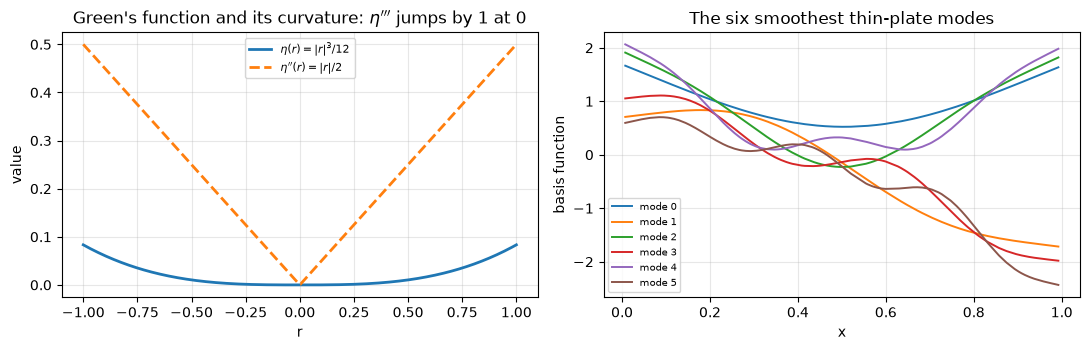

In [4]:
# --- tp, checked three ways -------------------------------------------------
X_tp, S_tp, meta_tp = build_smooth_basis(x, bs="tp", k=10)
print("tp metadata:", {k: meta_tp[k] for k in ("bs", "k", "M", "rank", "null_space_dim")})

evals = np.linalg.eigvalsh(S_tp[0])
print("penalty spectrum, smallest 4:", evals[:4])
print("penalty rank (non-zero eigenvalues):", np.linalg.matrix_rank(S_tp[0], tol=1e-8))

# (1) the Green's function: eta''(r) = |r|/2, so eta''' jumps by 1 across r = 0
r_pos = np.linspace(1e-3, 1.0, 400)
r_neg = -r_pos
h_eta = 1e-3
d2_pos = (_eta_1d(r_pos + h_eta) - 2 * _eta_1d(r_pos) + _eta_1d(r_pos - h_eta)) / h_eta**2
d2_neg = (_eta_1d(r_neg + h_eta) - 2 * _eta_1d(r_neg) + _eta_1d(r_neg - h_eta)) / h_eta**2
slope_pos = float(np.polyfit(r_pos, d2_pos, 1)[0])       # eta'' = +r/2 on the right
slope_neg = float(np.polyfit(r_neg, d2_neg, 1)[0])       # eta'' = -r/2 on the left
jump = slope_pos - slope_neg
print(f"eta''(r) slope: {slope_pos:+.4f} for r>0, {slope_neg:+.4f} for r<0"
      f"  ->  jump in eta''' at 0 = {jump:.4f}  (theory: 1)")

# (2) the pairing identity: delta' E delta == integral f''^2 dx
sites = np.array([0.0, 0.3, 0.6])
T = np.column_stack([np.ones(3), sites])                # null space of the TPS
delta = np.array([1.0, -2.0, 1.0])
delta = delta - T @ np.linalg.lstsq(T, delta, rcond=None)[0]   # enforce T'delta = 0
E = _eta_1d(sites[:, None] - sites[None, :])
quad = float(delta @ E @ delta)

g = np.linspace(-0.5, 1.1, 200001)
f_vals = sum(d * _eta_1d(np.abs(g - s)) for d, s in zip(delta, sites))
f_pp = np.gradient(np.gradient(f_vals, g), g)
integral = float(np.trapezoid(f_pp**2, g))
print(f"delta'E delta = {quad:.6f}   numeric integral of f''^2 = {integral:.6f}")
print(f"relative difference = {abs(quad - integral) / integral:.2e}")

# (3) sanity: the last two columns of the basis ARE the constant and the linear
# function, and the penalty has exactly zero rows/columns on those coefficients
print("last two basis columns reproduce 1 and (x - mean), scaled:",
      bool(np.allclose(X_tp[:, -2], 1.0 / meta_tp["col_rms"][-2])),
      bool(np.allclose(X_tp[:, -1], (x - x.mean()) / meta_tp["col_rms"][-1])))
print("penalty mass on the null-space coefficients:",
      float(np.abs(S_tp[0][-2:, :]).max()), float(np.abs(S_tp[0][:, -2:]).max()))

assert abs(jump - 1.0) < 0.01
assert abs(quad - integral) / integral < 1e-4
assert np.allclose(X_tp[:, -2], 1.0 / meta_tp["col_rms"][-2])
assert np.allclose(X_tp[:, -1], (x - x.mean()) / meta_tp["col_rms"][-1])
assert np.abs(S_tp[0][-2:, :]).max() == 0.0 and np.abs(S_tp[0][:, -2:]).max() == 0.0
assert meta_tp["rank"] == 8 and meta_tp["null_space_dim"] == 2

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
r_all = np.linspace(-1.0, 1.0, 400)
axes[0].plot(r_all, _eta_1d(r_all), lw=2, label=r"$\eta(r)=|r|^3/12$")
axes[0].plot(r_all, np.abs(r_all) / 2, "--", lw=2, label=r"$\eta''(r)=|r|/2$")
axes[0].set(xlabel="r", ylabel="value",
            title=r"Green's function and its curvature: $\eta'''$ jumps by 1 at 0")
axes[0].legend(fontsize=8)
axes[0].grid(alpha=0.3)
for j, col in enumerate(X_tp[:, :6].T):
    axes[1].plot(x, col, lw=1.4, label=f"mode {j}")
axes[1].set(xlabel="x", ylabel="basis function", title="The six smoothest thin-plate modes")
axes[1].legend(fontsize=7)
axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Shrinkage: `ts` and `cs`

A `tp` penalty has a two-dimensional null space, so $\lambda$ can flatten the
wiggly part but never remove the linear trend. The shrinkage variants fix that by
eigen-decomposing $S$ and charging the null-space eigenvalues a token amount:
for `ts`, $\;\text{ev}_0, \text{ev}_1 \leftarrow 0.1 \times \text{ev}_2$ (the
smallest positive eigenvalue); for `cs`, the two smallest get $0.1\times$ and
$0.01\times$ the smallest positive one, so the linear trend is charged *even
less* than for `ts`.

The consequence is a model-selection gift: with a shrinkage basis, a term that
does not earn its place is pushed to zero EDF by the estimator itself. You can
therefore leave a `ts` term in the formula and let REML decide whether it exists.

tp   null-space eigenvalues: [ 0.      0.     19.9042]  -> ts: [ 1.9904  1.9904 19.9042]
cr   null-space eigenvalues: [-0.     -0.     40.9449]  -> cs: [ 0.4094  4.0945 40.9449]

 
Family: gaussian 
Link function: identity 

Formula: s(0, bs='ts') + s(1, bs='ts')

Parametric coefficients:
            Estimate Std. Error t value Pr(>|t|)
(Intercept)     0.0104     0.0107   0.974   0.3315

Approximate significance of smooth terms:
        edf Ref.df      F p-value
s(0)      8.00      9 562.564 1.11e-16
s(1)      0.46      9  1.823   0.1786

R-sq.(adj) = 0.9577   Deviance explained = 95.9%
REML =   -70.5531  Scale est. = 0.0230   n = 200

EDF per term: [8.002497008556668, 0.4585220864366782]
estimated sp per term: [0.004174502346250141, 1461.4590991883586]


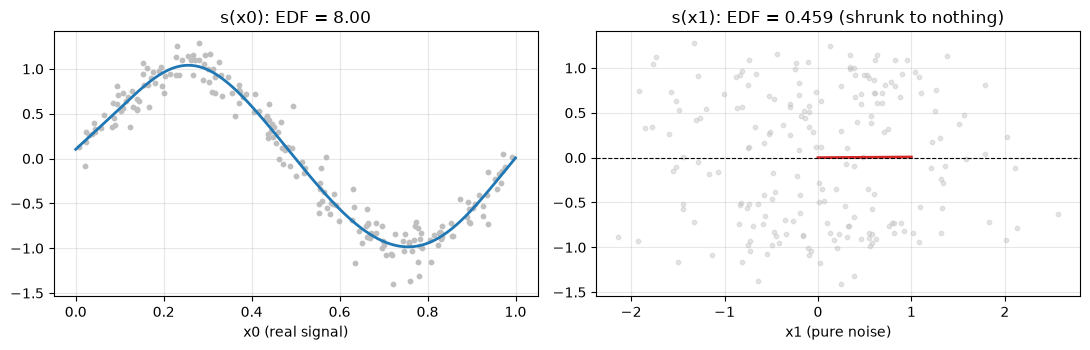

In [5]:
base_tp = np.linalg.eigvalsh(build_smooth_basis(x, bs="tp", k=10)[1][0])
shrink_ts = np.linalg.eigvalsh(build_smooth_basis(x, bs="ts", k=10)[1][0])
base_cs = np.linalg.eigvalsh(build_smooth_basis(x, bs="cr", k=10)[1][0])
shrink_cs = np.linalg.eigvalsh(build_smooth_basis(x, bs="cs", k=10)[1][0])

print("tp   null-space eigenvalues:", base_tp[:3], " -> ts:", shrink_ts[:3])
print("cr   null-space eigenvalues:", base_cs[:3], " -> cs:", shrink_cs[:3])

# Check the recipe: ev0, ev1 <- 0.1 * ev2 for 'ts' (0.1 and 0.01 for 'cs')
assert np.allclose(shrink_ts[:2], 0.1 * base_tp[2], rtol=1e-6)
assert np.allclose(shrink_cs[:2], [0.01 * base_cs[2], 0.1 * base_cs[2]], rtol=1e-6)

# A term that earns nothing: a pure-noise covariate next to a real signal
rng_shrink = np.random.default_rng(11)
X_shrink = np.column_stack([x, rng_shrink.normal(0.0, 1.0, n)])
y_shrink = f_true + rng_shrink.normal(0.0, 0.15, n)
m_shrink = GAMCore("s(0, bs='ts') + s(1, bs='ts')", backend="wood").fit(X_shrink, y_shrink)
curve_signal = m_shrink.partial_dependence(0, np.column_stack([x_grid, np.full_like(x_grid, -0.5)]))
curve_noise = m_shrink.partial_dependence(1, np.column_stack([np.full_like(x_grid, 0.5), x_grid]))

print("\n", m_shrink.summary())
print("EDF per term:", m_shrink.statistics_["edf_per_term"])
print("estimated sp per term:", m_shrink.statistics_["sp"])

assert m_shrink.statistics_["edf_per_term"][1] < 0.5, "the noise term must collapse"
assert m_shrink.statistics_["p_values_per_term"][1] > 0.05, "and be reported as insignificant"

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].scatter(X_shrink[:, 0], y_shrink, s=10, color="0.75")
axes[0].plot(x_grid, y_shrink.mean() + curve_signal, "C0-", lw=2)
axes[0].set(xlabel="x0 (real signal)", title="s(x0): EDF = %.2f" % m_shrink.statistics_["edf_per_term"][0])
axes[0].grid(alpha=0.3)
axes[1].scatter(X_shrink[:, 1], y_shrink - y_shrink.mean(), s=10, color="0.75", alpha=0.4)
axes[1].plot(x_grid, curve_noise, "C3-", lw=2)
axes[1].axhline(0, color="k", lw=0.8, ls="--")
axes[1].set(xlabel="x1 (pure noise)", title="s(x1): EDF = %.3f (shrunk to nothing)"
            % m_shrink.statistics_["edf_per_term"][1])
axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 2.2 `cr` / `cs`: cubic regression splines

`tp` is elegant but dense and defined by an eigen-problem. The workhorse
alternative places **knots** and does calculus *between* them. For `cr`:

* knots at the sample **quantiles** of the unique covariate values;
* $f$ is a cubic polynomial on each interval between knots;
* $f$, $f'$ and $f''$ are continuous at every knot;
* $f'' = 0$ beyond the first and last knot — the *natural* boundary condition,
  which makes the extrapolation exactly **linear**.

Rather than parameterising by the cubic coefficients, use the **value-curvature
parameterisation**: a natural cubic spline on $[x_j, x_{j+1}]$ is determined by
its values $f_j, f_{j+1}$ and its second derivatives $\gamma_j, \gamma_{j+1}$:

$$f(x) =
\frac{(x_{j+1}-x)^3 - h_j^2 (x_{j+1}-x)}{6 h_j}\,\gamma_j
+\frac{(x-x_j)^3 - h_j^2 (x-x_j)}{6 h_j}\,\gamma_{j+1}
+\frac{x_{j+1}-x}{h_j}\,f_j
+\frac{x-x_j}{h_j}\,f_{j+1},
\qquad h_j = x_{j+1}-x_j .$$

Continuity of the *first* derivative then gives the two linear systems that make
everything else cheap:

$$\underbrace{\boldsymbol{\gamma} = B^{-1} D\, \mathbf{f}}_{\text{curvatures from values}},
\qquad
S = D^\top B^{-1} D,$$

where $D$ is the $(n_k - 2)\times n_k$ divided-second-difference matrix

$$D = \begin{pmatrix}
\frac{1}{h_1} & -\left(\frac{1}{h_1}+\frac{1}{h_2}\right) & \frac{1}{h_2} & & \\
 & \frac{1}{h_2} & -\left(\frac{1}{h_2}+\frac{1}{h_3}\right) & \frac{1}{h_3} & \\
 & & \ddots & \ddots & \ddots
\end{pmatrix},$$

and $B$ is symmetric tridiagonal with diagonal $(h_j + h_{j+1})/3$ and off-diagonal
$h_{j+1}/6$. The curvature integral is then the quadratic form

$$\int f''(x)^2\,dx = \boldsymbol{\gamma}^\top B\, \boldsymbol{\gamma}
                   = \mathbf{f}^\top D^\top B^{-1} D\, \mathbf{f}.$$

Because a line has no curvature, $S$ has rank $k-2$: constants and slopes are
free. That is the null space you can see in Part I when $\lambda \to \infty$.

In [6]:
# --- rebuild D and B from the formulas above and check them against the library
X_cr, S_cr, meta_cr = build_smooth_basis(x, bs="cr", k=9)
xk = meta_cr["xp"]              # the quantile knots
h = np.diff(xk)

D = np.zeros((len(xk) - 2, len(xk)))
ii = np.arange(len(xk) - 2)
D[ii, ii] = 1.0 / h[:-1]
D[ii, ii + 1] = -(1.0 / h[:-1] + 1.0 / h[1:])
D[ii, ii + 2] = 1.0 / h[1:]

B = np.zeros((len(xk) - 2, len(xk) - 2))
for j in range(len(xk) - 2):
    B[j, j] = (h[j] + h[j + 1]) / 3.0
for j in range(len(xk) - 3):
    B[j, j + 1] = B[j + 1, j] = h[j + 1] / 6.0

S_hand = D.T @ np.linalg.solve(B, D)
print("S from the formula vs the library:  max |difference| =",
      float(np.abs(S_hand - S_cr[0]).max()))

# --- the curvature identity: gamma' B gamma == integral f''^2 (numerically)
f_knot = np.random.default_rng(3).normal(size=len(xk))
gamma = np.linalg.solve(B, D @ f_knot)
quad = float(gamma @ B @ gamma)
F_curv = np.zeros((len(xk), len(xk)))
F_curv[1:-1, :] = np.linalg.solve(B, D)

g = np.linspace(xk[0], xk[-1], 20001)
Xg = np.zeros((g.size, len(xk)))
for j in range(len(xk) - 1):
    m = (g >= xk[j]) & (g <= xk[j + 1])
    a, b = (xk[j + 1] - g[m]) / h[j], (g[m] - xk[j]) / h[j]
    Xg[m, j] += a
    Xg[m, j + 1] += b
    cjm = ((xk[j + 1] - g[m]) ** 3 / h[j] - h[j] * (xk[j + 1] - g[m])) / 6.0
    cjp = ((g[m] - xk[j]) ** 3 / h[j] - h[j] * (g[m] - xk[j])) / 6.0
    Xg[m, :] += cjm[:, None] * F_curv[j, :] + cjp[:, None] * F_curv[j + 1, :]
spline = Xg @ f_knot
spline_pp = np.gradient(np.gradient(spline, g), g)
integral = float(np.trapezoid(spline_pp**2, g))
print(f"gamma' B gamma = {quad:.6f}   numeric integral = {integral:.6f}"
      f"   relative difference = {abs(quad - integral) / integral:.2e}")

# --- the null space is exactly the straight lines
print("S @ 1      :", float(np.abs(S_cr[0] @ np.ones(len(xk))).max()))
print("S @ knots  :", float(np.abs(S_cr[0] @ xk).max()))
print("S @ knots^2:", float(np.abs(S_cr[0] @ xk**2).max()))
print("rank of S  :", np.linalg.matrix_rank(S_cr[0], tol=1e-8), "of k =", len(xk))

assert np.abs(S_hand - S_cr[0]).max() < 1e-8
assert abs(quad - integral) / integral < 1e-4
assert np.abs(S_cr[0] @ np.ones(len(xk))).max() < 1e-8
assert np.abs(S_cr[0] @ xk).max() < 1e-8
assert np.abs(S_cr[0] @ xk**2).max() > 1.0
assert np.linalg.matrix_rank(S_cr[0], tol=1e-8) == len(xk) - 2

S from the formula vs the library:  max |difference| = 1.8189894035458565e-12
gamma' B gamma = 126499.595605   numeric integral = 126499.488807   relative difference = 8.44e-07
S @ 1      : 2.0168311465340594e-12
S @ knots  : 1.0892137847023208e-12
S @ knots^2: 26.347780538741723
rank of S  : 7 of k = 9


second differences in the extrapolation region: max |.| = 2.6645352591003757e-15


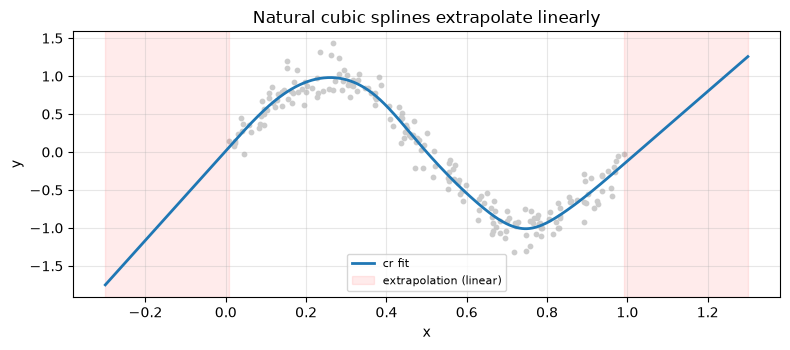

In [7]:
# --- the natural boundary condition in action: linear extrapolation
m_cr = LinGAM(k=9, bs="cr", backend="wood").fit(x, y)
x_wide = np.linspace(-0.3, 1.3, 801)
pred_wide = m_cr.predict(x_wide)
left = x_wide < m_cr.knots_.min()
right = x_wide > m_cr.knots_.max()

second_diffs = np.concatenate([np.diff(pred_wide[left], 2), np.diff(pred_wide[right], 2)])
print("second differences in the extrapolation region: max |.| =",
      float(np.abs(second_diffs).max()))

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.scatter(x, y, s=10, color="0.8")
ax.plot(x_wide, pred_wide, "C0-", lw=2, label="cr fit")
ax.axvspan(x_wide[0], m_cr.knots_.min(), color="red", alpha=0.08, label="extrapolation (linear)")
ax.axvspan(m_cr.knots_.max(), x_wide[-1], color="red", alpha=0.08)
ax.set(xlabel="x", ylabel="y", title="Natural cubic splines extrapolate linearly")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

assert np.abs(second_diffs).max() < 1e-9, "outside the knots a natural cubic spline is a straight line"

## 2.3 `cc` / `cp`: cyclic smooths

For a covariate that lives on a circle (hour of day, wind direction, phase of a
cycle) the two ends of the interval are the same point, so we demand
$f(x_0) = f(x_1)$ *and* matching derivatives. The cyclic cubic spline takes the
`cr` construction and **wraps** it: the last interval joins back to the first, so
the $B$ and $D$ matrices become *circulant*, e.g.

$$B_{0,0} = \frac{h_{n-1}+h_0}{3},\qquad
  B_{0,1} = \frac{h_0}{6},\qquad
  B_{0,n-1} = \frac{h_{n-1}}{6},$$

with mirrored entries in the last row. The penalty keeps the same form
$S = D^\top B^{-1} D$ but now has a **one-dimensional** null space: a periodic
function that is also straight must be constant. `cp` is the P-spline twin
(wrapped B-splines and a wrapped difference penalty).

Practical note: the cyclic basis wraps the covariate modulo the knot range, so
you should tell it where the period *starts and ends* with `knots=(lo, hi)`
rather than letting it use the data range. We will use the 24-hour day.


Family: gaussian 
Link function: identity 

Formula: s(0, bs='cc', k=12, knots=(0.0, 24.0))

Parametric coefficients:
            Estimate Std. Error t value Pr(>|t|)
(Intercept)    14.4780     0.0732 197.867        0

Approximate significance of smooth terms:
        edf Ref.df      F p-value
s(0)      8.22     11 668.249 1.11e-16

R-sq.(adj) = 0.9650   Deviance explained = 96.6%
REML =   307.0870  Scale est. = 1.0708   n = 200



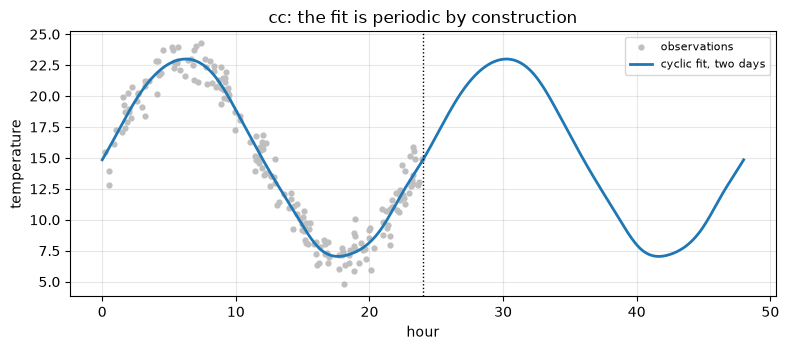

f(6)  vs f(30): difference = 0.00e+00
f(0)  vs f(24): difference = 0.00e+00
EDF: 9.222 of k-1 = 11


In [8]:
rng_cc = np.random.default_rng(4)
hour = rng_cc.uniform(0.0, 24.0, 200)
temp = 15.0 + 8.0 * np.sin(2 * np.pi * hour / 24.0) + rng_cc.normal(0.0, 1.0, hour.size)

m_cc = GAMCore("s(0, bs='cc', k=12, knots=(0.0, 24.0))", backend="wood").fit(hour.reshape(-1, 1), temp)
print(m_cc.summary())

day = np.linspace(0.0, 24.0, 500)
two_days = np.linspace(0.0, 48.0, 1000)

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.scatter(hour, temp, s=12, color="0.75", label="observations")
ax.plot(two_days, m_cc.predict(two_days.reshape(-1, 1)), "C0-", lw=2, label="cyclic fit, two days")
ax.axvline(24.0, color="k", ls=":", lw=1)
ax.set(xlabel="hour", ylabel="temperature", title="cc: the fit is periodic by construction")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

wrap_diff = abs(float(m_cc.predict([[6.0]])[0]) - float(m_cc.predict([[30.0]])[0]))
same_day = abs(float(m_cc.predict([[0.0]])[0]) - float(m_cc.predict([[24.0]])[0]))
print(f"f(6)  vs f(30): difference = {wrap_diff:.2e}")
print(f"f(0)  vs f(24): difference = {same_day:.2e}")
print("EDF:", round(m_cc.statistics_["edof"], 3), "of k-1 =", 11)

assert wrap_diff < 1e-10 and same_day < 1e-10

## 2.4 `ps`, `cp`, `bs`: B-splines and difference penalties

Cubic regression splines pay for their elegance with a matrix inverse
($B^{-1}$). Eilers and Marx (1996) cut the problem further: put a **uniform**
grid of knots, build B-splines on it, and penalise the *$m$-th order differences*
of adjacent coefficients:

$$S = D^\top D, \qquad D = \Delta^m \quad ((k-m)\times k).$$

With $m=2$, $S$ is the discrete analogue of curvature, and its null space is the
polynomials of degree $< m$ — linear trends stay free, exactly as for `cr`.
Because $D^\top D$ needs no inverse and is banded, P-splines are fast and
numerically friendly.

`bs` is the compromise: B-spline basis functions (like `ps`) but the *exact*
integrated-squared-derivative penalty

$$S_{ij} = \int B_i^{(m_2)}(x)\, B_j^{(m_2)}(x)\,dx,$$

computed by Gauss-Legendre quadrature over the knot spans. It is dense where
`ps` is banded, and needs no differencing approximation.

Conventions in this backend: `m=(m_basis, m_pen)`; for `ps`/`cp` the default is
`m=(2, 2)` (quadratic B-splines, second differences); for `bs` it is `m=(3, 2)`
(cubic B-splines, second-derivative penalty).

ps: max |S - D'D| = 0.0
ps rank = 10 (theory k - m = 10 )
bs rank = 10 (theory k - m2 = 10 )
null space tests (should be ~0 for 1 and x, non-zero for x^2):
  ps: |S 1|=0.00e+00  |S x|=8.88e-16  |S x^2|=0.017
  bs: |S 1|=4.55e-13  |S x|=4.55e-13  |S x^2|=6.266


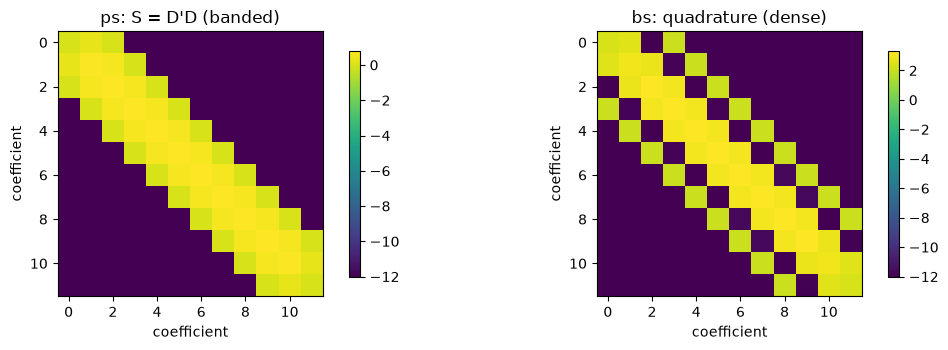

In [9]:
k = 12
X_ps, S_ps, meta_ps = build_smooth_basis(x, bs="ps", k=k, m=(2, 2))
X_bs, S_bs, meta_bs = build_smooth_basis(x, bs="bs", k=k, m=(3, 2))

D2 = np.diff(np.eye(k), n=2, axis=0)
print("ps: max |S - D'D| =", float(np.abs(S_ps[0] - D2.T @ D2).max()))
print("ps rank =", np.linalg.matrix_rank(S_ps[0], tol=1e-8), "(theory k - m =", k - 2, ")")
print("bs rank =", np.linalg.matrix_rank(S_bs[0], tol=1e-8), "(theory k - m2 =", k - 2, ")")
print("null space tests (should be ~0 for 1 and x, non-zero for x^2):")
for S, name in ((S_ps[0], "ps"), (S_bs[0], "bs")):
    print(f"  {name}: |S 1|={np.abs(S @ np.ones(k)).max():.2e}  "
          f"|S x|={np.abs(S @ np.linspace(0, 1, k)).max():.2e}  "
          f"|S x^2|={np.abs(S @ np.linspace(0, 1, k) ** 2).max():.3f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, S, name in ((axes[0], S_ps[0], "ps: S = D'D (banded)"), (axes[1], S_bs[0], "bs: quadrature (dense)")):
    im = ax.imshow(np.log10(np.abs(S) + 1e-12), cmap="viridis")
    ax.set(title=name, xlabel="coefficient", ylabel="coefficient")
    plt.colorbar(im, ax=ax, shrink=0.85)
plt.tight_layout()
plt.show()

assert np.abs(S_ps[0] - D2.T @ D2).max() < 1e-12
assert np.linalg.matrix_rank(S_ps[0], tol=1e-8) == k - 2
assert np.abs(S_bs[0] @ np.ones(k)).max() < 1e-10
assert np.abs(S_bs[0] @ np.linspace(0, 1, k)).max() < 1e-10
assert np.abs(S_bs[0] @ np.linspace(0, 1, k) ** 2).max() > 1.0

## 2.5 `re`: random-effect (ridge) smooths

For a categorical predictor you can use `f(x)` (a fixed factor term) or
`s(x, bs='re')`, which builds one indicator column per level and charges

$$S = I \qquad\Longrightarrow\qquad \boldsymbol{\beta}^\top S \boldsymbol{\beta} = \sum_j \beta_j^2 .$$

Pure ridge shrinking. In the Bayesian reading of Part V this *is* a
random-effects model: the level effects are drawn from
$N(0, \sigma^2/\lambda)$, and $\lambda$ estimated from the data is the
inverse variance of that random effect. Large $\lambda$ shrinks levels together
(pooling); small $\lambda$ keeps them apart.

Two small print details: the basis ignores `k` (there is one column per observed
level), and because `Ref.df` in the summary is printed from the requested `k`,
the number you see there is not the number of coefficients. Trust what the fitted
term reports through `_terms[...].n_coefs`, or just compare EDF with the level
count.

In [10]:
rng_re = np.random.default_rng(6)
levels = rng_re.integers(0, 6, n).astype(float)
X_re = np.column_stack([x, levels])
y_re = f_true + np.where(levels == 3, 1.0, 0.0) + rng_re.normal(0.0, 0.15, n)

m_re = GAMCore("s(0, k=8, bs='cr') + s(1, bs='re')", backend="wood").fit(X_re, y_re)
print(m_re.summary())
print("coefficients in the re term:", m_re._terms[1].n_coefs, "levels:", len(np.unique(levels)))
print("EDF of the re term:", round(m_re.statistics_["edf_per_term"][1], 3))
print("estimated sp:", np.round(m_re.statistics_["sp"], 4), "(1/sp is the effect variance)")

n_levels = len(np.unique(levels))
assert 0.8 * (n_levels - 1) < m_re.statistics_["edf_per_term"][1] <= n_levels - 1 + 1e-9


Family: gaussian 
Link function: identity 

Formula: s(0, k=8, bs='cr') + s(1, bs='re')

Parametric coefficients:
            Estimate Std. Error t value Pr(>|t|)
(Intercept)     0.1586     0.0106  14.904        0

Approximate significance of smooth terms:
        edf Ref.df      F p-value
s(0)      6.73      7 699.349 1.11e-16
s(1)      4.98      9 224.963 1.11e-16

R-sq.(adj) = 0.9663   Deviance explained = 96.8%
REML =   -63.2665  Scale est. = 0.0226   n = 200

coefficients in the re term: 5 levels: 6
EDF of the re term: 4.979
estimated sp: [1.1999 0.135 ] (1/sp is the effect variance)


---
# Part III. Identifiability: `S.scale` and the sum-to-zero constraint

A fitted GAM with an intercept is over-parametrised: add a constant to a smooth
and subtract it from the intercept and every prediction is unchanged. The fit
still "works", but the decomposition becomes arbitrary, and the reported
coefficients are not interpretable. The Wood backend removes the ambiguity with
two standard moves applied to **every** smooth before fitting.

**Move 1 — rescale every penalty.** The raw size of $S$ depends on the basis
(large-magnitude basis functions produce a large penalty), so the same $\lambda$
would mean different amounts of smoothing for different terms. Normalise by

$$\mathrm{S.scale}_i = \frac{\|S_i\|_O}{\|X\|_I^2},
\qquad S_i \leftarrow \frac{S_i}{\mathrm{S.scale}_i},$$

where $\|S\|_O$ is the maximum column sum (the operator norm for a symmetric
matrix) and $\|X\|_I$ is the maximum row sum, squared. After this, $S_i$ is
scaled so that its own maximum column sum equals **that term's** $\|X\|_I^2$, so
"one unit of $\lambda$" means the same thing — penalty strength relative to the
data term — for every term and every basis family, even though the raw entries of
`S` differ wildly between bases. The scale is stored in `S.scale`, so the reported
`sp` values are all on this normalised scale.

**Move 2 — absorb the sum-to-zero constraint.** Require each smooth to be centred,

$$C\boldsymbol{\beta} = 0, \qquad C = \mathbf{1}^\top X
\quad\text{(the row of column sums)}.$$

Instead of solving a constrained problem, the constraint is *absorbed into the
basis*. QR-decompose $C^\top$ (a $k\times 1$ matrix), take
$Z = Q_{[:,1:]}$ — an orthonormal basis of $\ker C$ — and project everything:

$$\tilde X = X Z, \qquad \tilde S_i = Z^\top S_i Z,
\qquad \tilde\beta = Z^\top \beta .$$

Now $\mathbf{1}^\top \tilde X = 0$ *identically*: every smooth is centred by
construction, in every fit, at every $\lambda$, and in every prediction. The
intercept owns the level; each smooth owns only its shape. This is why the
decomposition panels of a Wood model are genuinely zero-centred.

 basis   max col sum S (raw)      S.scale  max col sum S (after)  ||X||_I^2
    tp               3850.44        14.03                 274.48     274.48
    cr              31893.28      9681.34                   3.29       3.29
    ps                 16.00        16.00                   1.00       1.00
    bs               1347.96      1347.96                   1.00       1.00
    cc              35871.73     10154.34                   3.53       3.53

||X||_I^2 for the cr basis = 3.2943048948204194

shape before absorption: (200, 9) -> after: (200, 8) (one constraint removed)
max |column sums of X~| = 1.529332216421153e-14


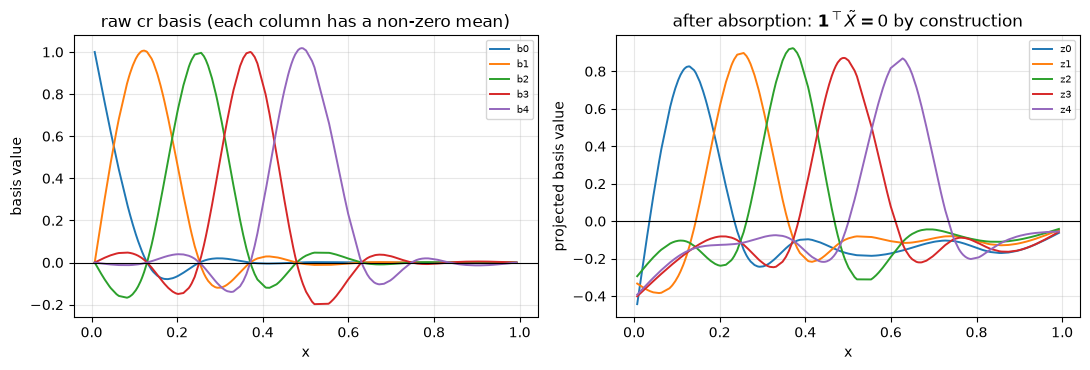

sample mean of the fitted partial effects (training rows): [0.0, 0.0]


In [11]:
# --- Move 1: what S.scale does ---------------------------------------------
print(f"{'basis':>6} {'max col sum S (raw)':>21} {'S.scale':>12} "
      f"{'max col sum S (after)':>22} {'||X||_I^2':>10}")
for bs_code in ("tp", "cr", "ps", "bs", "cc"):
    X_raw_b, S_raw_b, _ = build_smooth_basis(x, bs=bs_code, k=9)
    S_scaled_b, scales_b = rescale_penalty(X_raw_b, S_raw_b)
    norm_b = float(np.max(np.abs(X_raw_b).sum(axis=1)) ** 2)
    print(f"{bs_code:>6} {np.max(np.abs(S_raw_b[0]).sum(axis=0)):21.2f} {scales_b[0]:12.2f} "
          f"{np.max(np.abs(S_scaled_b[0]).sum(axis=0)):22.2f} {norm_b:10.2f}")

X_raw, S_raw, _ = build_smooth_basis(x, bs="cr", k=9)
S_scaled, scales = rescale_penalty(X_raw, S_raw)
norm_I_squared = float(np.max(np.abs(X_raw).sum(axis=1)) ** 2)
print("\n||X||_I^2 for the cr basis =", norm_I_squared)
assert abs(np.max(np.abs(S_scaled[0]).sum(axis=0)) - norm_I_squared) < 1e-6 * norm_I_squared

# --- Move 2: absorption ------------------------------------------------
X_t, S_t, Z = absorb_sum_to_zero_constraint(X_raw, S_scaled)
print("\nshape before absorption:", X_raw.shape, "-> after:", X_t.shape, "(one constraint removed)")
print("max |column sums of X~| =", float(np.abs(X_t.sum(axis=0)).max()))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for j in range(min(5, X_raw.shape[1])):
    axes[0].plot(x, X_raw[:, j], lw=1.4, label=f"b{j}")
axes[0].axhline(0, color="k", lw=0.8)
axes[0].set(xlabel="x", ylabel="basis value", title="raw cr basis (each column has a non-zero mean)")
axes[0].legend(fontsize=7)
axes[0].grid(alpha=0.3)
for j in range(min(5, X_t.shape[1])):
    axes[1].plot(x, X_t[:, j], lw=1.4, label=f"z{j}")
axes[1].axhline(0, color="k", lw=0.8)
axes[1].set(xlabel="x", ylabel="projected basis value",
            title=r"after absorption: $\mathbf{1}^\top \tilde X = 0$ by construction")
axes[1].legend(fontsize=7)
axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

assert np.abs(X_t.sum(axis=0)).max() < 1e-10

# --- the practical consequence: partial effects have zero sample mean ------
X_cent = np.column_stack([x, np.random.default_rng(8).uniform(0, 1, n)])
m_cent = GAMCore("s(0, k=10, bs='cr') + s(1, k=10, bs='tp')", backend="wood").fit(X_cent, y)
means = [float(np.mean(m_cent.partial_dependence(j, X_cent))) for j in range(2)]
print("sample mean of the fitted partial effects (training rows):", means)
assert max(abs(v) for v in means) < 1e-9

---
# Part IV. Fitting, for a fixed $\lambda$

With $X$ rescaled and the constraint absorbed, the objective is an ordinary
penalised least squares problem in $\tilde\beta$:

$$\hat{\tilde\beta}(\boldsymbol{\lambda}) =
\arg\min_{\beta}\ \|\mathbf{y} - \tilde X \beta\|^2 + \beta^\top \tilde S_{\boldsymbol\lambda} \beta .$$

Take the derivative: $\hat\beta = H^{-1}\tilde X^\top \mathbf{y}$ with

$$H = \tilde X^\top \tilde X + \tilde S_{\boldsymbol\lambda},$$,

which is symmetric positive definite and therefore solved with a Cholesky
factorisation $H = LL^\top$. Two quantities fall out of the same factorisation
for free:

$$\mathrm{EDF} = \operatorname{tr}\!\big(H^{-1}\tilde X^\top \tilde X\big)
\quad\text{(the influence matrix's trace)},$$

$$\mathrm{SE}_j = \sqrt{\hat\sigma^2\,(H^{-1})_{jj}},
\qquad \hat\sigma^2 = \frac{\mathrm{RSS}}{n - \mathrm{EDF}} .$$

The library is doing exactly this — let us confirm that by rebuilding its
coefficients by hand, using nothing but the four helper functions.

In [12]:
# --- assemble the design exactly the way the backend does -------------------
k_main = 9
X_raw, S_raw, meta = build_smooth_basis(x, bs="cr", k=k_main)
S_scaled, s_scale = rescale_penalty(X_raw, S_raw)
X_t, S_t, Z = absorb_sum_to_zero_constraint(X_raw, S_scaled)

X_design = np.column_stack([X_t, np.ones(n)])          # + intercept
S_design = np.pad(S_t[0], ((0, 1), (0, 1)))            # penalty block, padded with a zero row/col

# (a) fixed lambda: solve the normal equations by hand
lam = 5.0
H = X_design.T @ X_design + lam * S_design
H.flat[:: X_design.shape[1] + 1] += 1e-12              # the same 1e-12 ridge the library adds
beta_hand = np.linalg.solve(H, X_design.T @ y)
edf_hand = float(np.trace(np.linalg.solve(H, X_design.T @ X_design)))

fit_lam = fit_wood_engine(X_design, y, [S_design], sp_fixed=[lam], method="REML")
print("lambda =", lam)
print("max |beta_hand - beta_engine| =", float(np.abs(beta_hand - fit_lam["coef"]).max()))
print("EDF hand =", edf_hand, "   EDF engine =", fit_lam["edof"])

# (b) let the engine choose lambda, and compare with the public class
fit_free = fit_wood_engine(X_design, y, [S_design], sp_fixed=[None], method="REML")
model = LinGAM(k=k_main, bs="cr", backend="wood").fit(x, y)

print("\nengine:   sp =", fit_free["sp"][0], " score =", fit_free["score"], " edof =", fit_free["edof"])
print("LinGAM:   sp =", model.lam, " score =", model.statistics_["score"], " edof =", model.statistics_["edof"])
print("max |coefficients difference| =", float(np.abs(fit_free["coef"] - model.coef_).max()))
print("max |predictions difference|  =",
      float(np.abs(X_design @ fit_free["coef"] - model.predict(x)).max()))

assert np.abs(beta_hand - fit_lam["coef"]).max() < 1e-9
assert abs(edf_hand - fit_lam["edof"]) < 1e-9
assert np.abs(fit_free["coef"] - model.coef_).max() < 1e-10
assert abs(fit_free["sp"][0] - model.lam) < 1e-12

lambda = 5.0
max |beta_hand - beta_engine| = 9.992007221626409e-16
EDF hand = 7.774152447504363    EDF engine = 7.774152447504363

engine:   sp = 1.849985043325132  score = -73.52207849992935  edof = 8.404746001988636
LinGAM:   sp = 1.849985043325132  score = -73.52207849992935  edof = 8.404746001988636
max |coefficients difference| = 0.0
max |predictions difference|  = 0.0


### What EDF means coefficient by coefficient

The influence matrix is $F = H^{-1}\tilde X^\top \tilde X$, and EDF is its trace.
Its *diagonal* is more informative still: $F_{jj}$ is the "share of a parameter"
spent on coefficient $j$, and $\sum_j F_{jj} = \mathrm{EDF}$.

Three facts worth remembering:

* the intercept gets exactly 1 (it is unpenalised and orthogonal to every
  constraint-absorbed column);
* wiggly coefficients get much less than 1;
* a term's EDF is the sum of $F_{jj}$ over its block — `statistics_['edf_per_term']`
  gives you the same numbers the summary table prints.

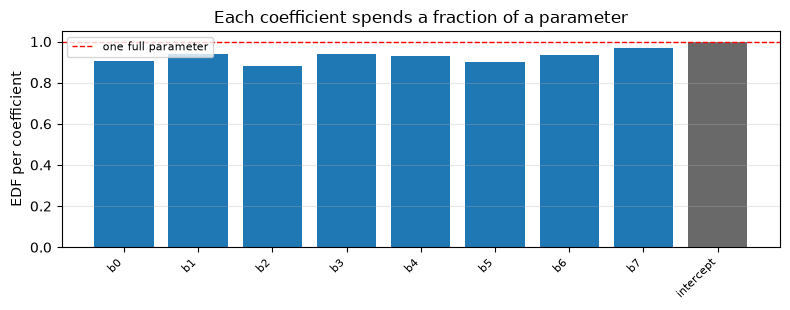

sum of per-coefficient EDF = 8.404746001988636   reported EDF = 8.404746001988636
intercept EDF = 0.9999999999999948


In [13]:
edof_coef = model.statistics_["edof_per_coef"]
labels = [f"b{j}" for j in range(edof_coef.size - 1)] + ["intercept"]

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.bar(range(edof_coef.size), edof_coef, color=["C0"] * (edof_coef.size - 1) + ["dimgray"])
ax.set_xticks(range(edof_coef.size))
ax.set_xticklabels(labels, rotation=45, ha="right", fontsize=8)
ax.axhline(1.0, color="r", ls="--", lw=1, label="one full parameter")
ax.set(ylabel="EDF per coefficient", title="Each coefficient spends a fraction of a parameter")
ax.legend(fontsize=8)
ax.grid(alpha=0.3, axis="y")
plt.tight_layout()
plt.show()

print("sum of per-coefficient EDF =", float(edof_coef.sum()),
      "  reported EDF =", model.statistics_["edof"])
print("intercept EDF =", float(edof_coef[-1]))

assert abs(edof_coef.sum() - model.statistics_["edof"]) < 1e-10
assert abs(edof_coef[-1] - 1.0) < 1e-6
assert np.all(edof_coef[:-1] < 1.0 + 1e-8)

---
# Part V. Choosing $\lambda$: GCV and REML

So far $\lambda$ was a knob we turned by hand. The Wood backend treats it as an
unknown parameter and *optimises* a model-selection criterion. Two criteria are
available; the default is REML.

## 5.1 GCV.Cp (the Eilers-Marx criterion)

$$\mathrm{GCV}(\boldsymbol\lambda) = \frac{n\cdot \mathrm{RSS}}{(n - \gamma\,\mathrm{EDF})^2},
\qquad \hat\sigma^2 = \frac{\mathrm{RSS}}{n - \mathrm{EDF}},$$

with $\gamma = 1$ in the Wood backend. It is the leave-one-out cross-validation
score computed from a single fit, which is why GCV is cheap — and also why it is
notoriously flat near the optimum and occasionally picks $\lambda \to 0$.

## 5.2 REML (the default)

Give the coefficients a Gaussian prior whose precision *is* the penalty:

$$\mathbf{y} = X\boldsymbol{\beta} + \boldsymbol{\varepsilon},
\quad \boldsymbol{\varepsilon}\sim N(0, \sigma^2 I),
\qquad \boldsymbol{\beta}\sim N\!\big(0,\ \sigma^2 S_{\boldsymbol\lambda}^{-}\big),$$

where $S_{\boldsymbol\lambda}^{-}$ is the *generalised* inverse: an improper
prior that treats the penalty's null space as infinite variance (those directions
are unpenalised, so they must be estimated from the data alone).

Integrating $\boldsymbol\beta$ out gives the marginal likelihood. Profiling
$\sigma^2$ out at

$$\hat\sigma^2 = \frac{D_p}{n - M_p},
\qquad
D_p = \underbrace{\|\mathbf{y}-X\hat{\boldsymbol\beta}\|^2}_{\mathrm{RSS}}
    + \underbrace{\hat{\boldsymbol\beta}^\top S_{\boldsymbol\lambda}\hat{\boldsymbol\beta}}_{\text{penalty cost}},
\qquad
M_p = p - \operatorname{rank}(S_{\boldsymbol\lambda}),$$

leaves a criterion that is *only* a function of $\boldsymbol\lambda$:

$$\ell_r(\boldsymbol\lambda) =
\frac{D_p}{2\hat\sigma^2}
+ \frac{n - M_p}{2}\log(2\pi\hat\sigma^2)
+ \frac{1}{2}\log|H|
- \frac{1}{2}\log|S_{\boldsymbol\lambda}|_+ .$$

Read it term by term:

* $D_p / (2\hat\sigma^2)$ — how well the penalised fit explains the data, in units
  of the estimated noise. Combined with the next term it is just
  $(n-M_p)\,(1 + \log 2\pi\hat\sigma^2)/2$, a monotone function of the penalised
  deviance $D_p$;
* $+\tfrac12 \log|H|$ — a **complexity tax**. Weakening the penalty inflates the
  determinant of $H$ and worsens the score. This is the term that stops
  $\lambda \to 0$;
* $-\tfrac12 \log |S_{\boldsymbol\lambda}|_+$ — a normalisation correction for the
  prior. The subscript $+$ means *the product of the positive eigenvalues only*:
  the penalty is singular by design, and including its null space would give
  $\log 0 = -\infty$. For $S_\lambda = \lambda S$ with $\operatorname{rank}(S)=r$
  this scales correctly as $\log|S_\lambda|_+ = r\log\lambda + \log|S|_+$.

$M_p$ is the total *unpenalised* dimension of the model — the intercept plus any
unpenalised null-space directions of the smooths. Using $n - M_p$ instead of $n$
is what makes the likelihood *restricted*, and it is why REML does not
under-smooth the way plain maximum likelihood does: ML ignores the degrees of
freedom spent estimating $\boldsymbol\beta$ and biases $\hat\sigma^2$ (and hence
$\lambda$) downward.

**Optimisation.** $\lambda$ must be positive, so the backend optimises
$\rho = \log\lambda$ (unconstrained, $\lambda = e^\rho$) over $[-15, 15]$, starting
from the best point of a coarse grid $\rho_0 \in \{-8,-4,0,4,8\}$ and then running
L-BFGS-B with **analytic gradients**. Two identities make those gradients cheap:

$$\frac{\partial D_p}{\partial \rho_j} = \lambda_j\, \hat{\boldsymbol\beta}^\top S_j \hat{\boldsymbol\beta}
\qquad\text{(envelope theorem: the }\partial\hat\beta/\partial\rho\text{ terms cancel)},$$

$$\frac{\partial \log|H|}{\partial \rho_j} = \lambda_j \operatorname{tr}(H^{-1}S_j),
\qquad
\frac{\partial \log|S_{\boldsymbol\lambda}|_+}{\partial \rho_j} = \operatorname{rank}(S_j),$$

so nothing has to be re-solved or finite-differenced: everything comes from the
Cholesky factor already computed. We verify all of this numerically below.

In [14]:
# --- the two criteria, handwritten -----------------------------------------
def criteria(rho, X, y, S, gamma=1.0):
    # REML score, GCV score, EDF and RSS, written out exactly as in Part V
    n, p = X.shape
    lam = np.exp(rho)
    H = X.T @ X + lam * S
    H.flat[:: p + 1] += 1e-12
    H_inv = np.linalg.inv(H)
    beta = H_inv @ X.T @ y
    rss = float(np.sum((y - X @ beta) ** 2))
    Dp = rss + lam * float(beta @ S @ beta)                # penalised deviance
    edf = float(np.trace(H_inv @ (X.T @ X)))

    ev = np.linalg.eigvalsh(S)
    positive = ev > ev[-1] * 1e-10
    rank_S = int(positive.sum())
    M_p = p - rank_S                                       # unpenalised dimension
    log_det_S = float(np.sum(np.log(ev[positive]))) + rank_S * rho

    sigma2 = Dp / (n - M_p)
    log_det_H = float(np.linalg.slogdet(H)[1])
    reml = (Dp / (2 * sigma2)
            + 0.5 * (n - M_p) * np.log(2 * np.pi * sigma2)
            + 0.5 * log_det_H
            - 0.5 * log_det_S)
    gcv = (n * rss) / (n - gamma * edf) ** 2
    return reml, gcv, edf, rss


print(f"{'lambda':>10} {'REML hand':>12} {'REML engine':>13} {'GCV hand':>11} {'GCV engine':>12}")
for lam in (1e-3, 1.0, 100.0):
    reml_hand, gcv_hand, _, _ = criteria(np.log(lam), X_design, y, S_design)
    reml_eng = fit_wood_engine(X_design, y, [S_design], sp_fixed=[lam], method="REML")["score"]
    gcv_eng = fit_wood_engine(X_design, y, [S_design], sp_fixed=[lam], method="GCV.Cp")["score"]
    print(f"{lam:10.0e} {reml_hand:12.5f} {reml_eng:13.5f} {gcv_hand:11.6f} {gcv_eng:12.6f}")
    assert abs(reml_hand - reml_eng) < 1e-8
    assert abs(gcv_hand - gcv_eng) < 1e-10

    lambda    REML hand   REML engine    GCV hand   GCV engine
     1e-03    -50.89723     -50.89723    0.024595     0.024595
     1e+00    -73.01594     -73.01594    0.024515     0.024515
     1e+02     -1.27943      -1.27943    0.029685     0.029685


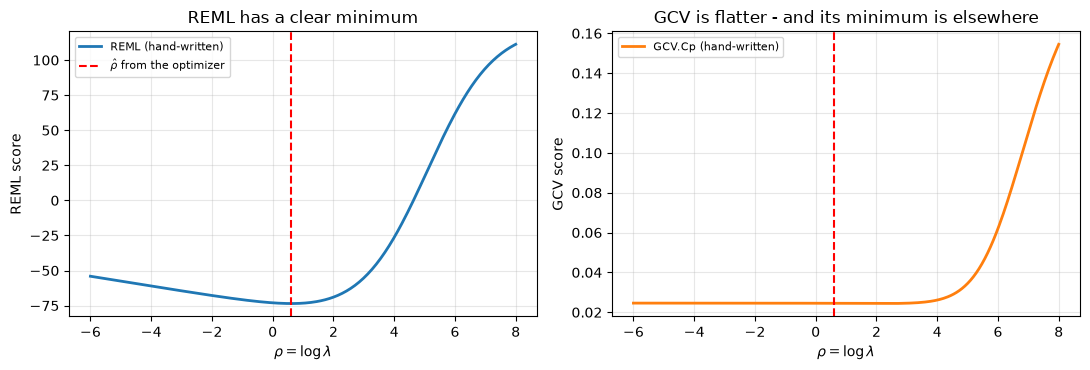

optimizer rho_hat            = 0.6152   (lambda = 1.8500)
hand-written grid argmin     = 0.6020
EDF at the optimizer optimum = 8.4047
EDF at the GCV optimum       = 7.3591

flatness on rho in (0, 3):  REML range = 18.0723,  GCV range = 0.000159


In [15]:
# --- the landscape, and where the optimiser lands ---------------------------
rho_grid = np.linspace(-6.0, 8.0, 300)
curve_reml = np.array([criteria(r, X_design, y, S_design)[0] for r in rho_grid])
curve_gcv = np.array([criteria(r, X_design, y, S_design)[1] for r in rho_grid])

rho_hat = float(np.log(model.lam))
rho_grid_min = float(rho_grid[np.argmin(curve_reml)])

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(rho_grid, curve_reml, lw=2, label="REML (hand-written)")
axes[0].axvline(rho_hat, color="r", ls="--", label=r"$\hat\rho$ from the optimizer")
axes[0].set(xlabel=r"$\rho = \log\lambda$", ylabel="REML score",
            title="REML has a clear minimum")
axes[0].legend(fontsize=8)
axes[0].grid(alpha=0.3)
axes[1].plot(rho_grid, curve_gcv, lw=2, color="C1", label="GCV.Cp (hand-written)")
axes[1].axvline(rho_hat, color="r", ls="--")
axes[1].set(xlabel=r"$\rho = \log\lambda$", ylabel="GCV score", title="GCV is flatter - and its minimum is elsewhere")
axes[1].legend(fontsize=8)
axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f"optimizer rho_hat            = {rho_hat:.4f}   (lambda = {np.exp(rho_hat):.4f})")
print(f"hand-written grid argmin     = {rho_grid_min:.4f}")
print(f"EDF at the optimizer optimum = {criteria(rho_hat, X_design, y, S_design)[2]:.4f}")
print(f"EDF at the GCV optimum       = {criteria(rho_grid[np.argmin(curve_gcv)], X_design, y, S_design)[2]:.4f}")
window = (rho_grid > 0) & (rho_grid < 3)
print(f"\nflatness on rho in (0, 3):  REML range = {np.ptp(curve_reml[window]):.4f},"
      f"  GCV range = {np.ptp(curve_gcv[window]):.6f}")

assert abs(rho_hat - rho_grid_min) < 0.05, "the optimizer must find the grid minimum"

In [16]:
# --- analytic gradient vs finite differences --------------------------------
def reml_grad_analytic(rho, X, y, S):
    # the gradient formula from the text: 0.5 * (dDp/sigma^2 + dlogH - dlogS)
    n, p = X.shape
    lam = np.exp(rho)
    H = X.T @ X + lam * S
    H.flat[:: p + 1] += 1e-12
    H_inv = np.linalg.inv(H)
    beta = H_inv @ X.T @ y
    rss = float(np.sum((y - X @ beta) ** 2))
    Dp = rss + lam * float(beta @ S @ beta)
    ev = np.linalg.eigvalsh(S)
    rank_S = int(np.sum(ev > ev[-1] * 1e-10))
    sigma2 = Dp / (n - (p - rank_S))
    dDp = lam * float(beta @ S @ beta)                    # envelope theorem
    dlogH = lam * float(np.sum(H_inv * S))                # lambda * tr(H^-1 S)
    return 0.5 * (dDp / sigma2 + dlogH - rank_S)


h = 1e-6
print(f"{'rho':>6} {'analytic':>12} {'finite diff':>13} {'rel. difference':>16}")
for rho_test in (-2.0, 0.0, 1.0, 2.0):
    a = reml_grad_analytic(rho_test, X_design, y, S_design)
    fd = (criteria(rho_test + h, X_design, y, S_design)[0]
          - criteria(rho_test - h, X_design, y, S_design)[0]) / (2 * h)
    rel = abs(a - fd) / max(abs(fd), 1e-12)
    print(f"{rho_test:6.2f} {a:12.5f} {fd:13.5f} {rel:16.2e}")
    assert rel < 1e-5

print("\ngradient at the optimum (should be ~0):",
      round(float(reml_grad_analytic(rho_hat, X_design, y, S_design)), 8))
print("gradient just to the left / right:",
      round(float(reml_grad_analytic(rho_hat - 0.5, X_design, y, S_design)), 4),
      round(float(reml_grad_analytic(rho_hat + 0.5, X_design, y, S_design)), 4))
assert abs(reml_grad_analytic(rho_hat, X_design, y, S_design)) < 1e-4

   rho     analytic   finite diff  rel. difference
 -2.00     -3.21325      -3.21325         9.31e-10
  0.00     -1.51243      -1.51243         9.81e-09
  1.00      1.43319       1.43319         1.04e-08
  2.00      7.98842       7.98842         2.52e-09

gradient at the optimum (should be ~0): -0.0
gradient just to the left / right: -1.287 1.9573


### Pinning, multiple penalties, and searching over `k`

Three practical switches:

* `sp=` (or `lam=`) inside `s(...)` **pins** that term's smoothing parameter and
  lets REML estimate the others;
* with several smooths each penalty gets its own $\lambda_j$, and the optimiser
  runs in the correspondingly higher-dimensional $\rho$ space — the gradient
  formulas above apply coordinate by coordinate;
* `gridsearch` sweeps the basis dimension $k$ while REML optimises $\lambda$
  continuously inside each candidate.

In [17]:
# --- pinned + free in the same model ----------------------------------------
rng_multi = np.random.default_rng(9)
X_multi = rng_multi.uniform(0.0, 1.0, (n, 2))
y_multi = np.sin(2 * np.pi * X_multi[:, 0]) + 0.7 * X_multi[:, 1] + rng_multi.normal(0, 0.2, n)

m_mixed = GAMCore("s(0, k=10, bs='cr', sp=2.0) + s(1, k=8, bs='cr')", backend="wood").fit(X_multi, y_multi)
sp_values = [t.sp for t in m_mixed._terms]
print("term smoothing parameters (first is pinned):", sp_values)
print(m_mixed.summary())

assert sp_values[0][0] == 2.0
assert sp_values[1][0] != 2.0

# --- search over candidate basis dimensions ---------------------------------
m_k = GAMCore("s(0, bs='tp') + s(1, bs='tp')", backend="wood")
m_k.gridsearch(X_multi, y_multi, n_splines_grids=[np.arange(6, 13, 2)] * 2)
print("\ngridsearch picked k =", [t.k for t in m_k._terms],
      " with EDF =", round(m_k.statistics_["edof"], 3))

assert all(t.k in (6, 8, 10, 12) for t in m_k._terms)

term smoothing parameters (first is pinned): [[2.0], [3269017.3724721107]]

Family: gaussian 
Link function: identity 

Formula: s(0, k=10, bs='cr', sp=2.0) + s(1, k=8, bs='cr')

Parametric coefficients:
            Estimate Std. Error t value Pr(>|t|)
(Intercept)     0.3933     0.0147  26.796        0

Approximate significance of smooth terms:
        edf Ref.df      F p-value
s(0)      8.39      9 273.252 1.11e-16
s(1)      1.00      7 141.966 1.11e-16

R-sq.(adj) = 0.9255   Deviance explained = 92.9%
REML =    -8.9575  Scale est. = 0.0431   n = 200




gridsearch picked k = [8, 6]  with EDF = 8.602


Read the pinned-model output carefully, because it contains the most common
surprise in practical Wood fits: the *free* term's `sp` came out at `3.27e6` —
exactly $e^{15}$, the optimiser's upper bound — and its EDF is exactly 1.00.

That is not a failure. The covariate enters **linearly**, and a straight line
lives in the penalty's null space (Part II), so the criterion can push $\lambda$
up for ever without ever distorting the fit: infinitely smooth and least-squares
linear are the *same* model here. `sp` parked on the bound with EDF = 1 is the
estimator telling you "this effect is a straight line" — you can replace the
smooth with `l(j)`, get the same predictions, and read a cleaner summary.
Contrast with `ts`/`cs`, where a huge `sp` and an EDF near 0 means the term was
*removed*.

---
# Part VI. Inference: two covariances, one F-test

Once $\boldsymbol\lambda$ is estimated (and treated as *known* from here on) the
backend produces a complete inferential kit.

**Two covariance matrices**

$$V_p = H^{-1}\hat\sigma^2
\qquad\text{(Bayesian posterior: the prior from Part V, }\lambda\text{ fixed)},$$

$$V_e = H^{-1}X^\top X\,H^{-1}\hat\sigma^2
\qquad\text{(frequentist / sandwich: the sampling covariance of }\hat\beta).$$

`summary()` reports standard errors from $V_p$; confidence bands use
$\mathbf{x}^{*\top} V_p\, \mathbf{x}^*$ with $t$ quantiles on $n - \mathrm{EDF}$
degrees of freedom. Both ignore the uncertainty in $\hat\lambda$ — the standard
simplification in Wood (2011), which makes intervals slightly optimistic.

**Wood's approximate F-test (Wood 2013).** For each term, testing
$H_0: f_j = 0$, the statistic is

$$F_j = \frac{\hat{\boldsymbol\beta}_j^\top V_{p,j}^{-1} \hat{\boldsymbol\beta}_j}{\mathrm{EDF}_j}
\ \sim\ F(\mathrm{EDF}_j,\ n - \mathrm{EDF}),$$

with the p-value from the right tail. The justification is moment matching: under
the null, the quadratic form has mean $\mathrm{EDF}_j$ and variance
$2\,\mathrm{EDF}_j$, which matches an $F$ distribution to second order. It is
*approximate* — exact when $\lambda = 0$ (where it reduces to the classical
F-test) and unreliable when $\mathrm{EDF}_j$ is barely above 1. Treat p-values for
terms with EDF $\lesssim 1.5$ as "this term does nothing", not as a precise number.

**Model-level numbers**

$$\text{deviance explained} = 1 - \frac{\mathrm{RSS}}{\sum_i (y_i - \bar y)^2},
\qquad
R^2_{\text{adj}} = 1 - \frac{\mathrm{RSS}/(n-\mathrm{EDF})}{\mathrm{TSS}/(n-1)},$$

$$\ell = -\frac{n}{2}\log(2\pi\hat\sigma^2) - \frac{\mathrm{RSS}}{2\hat\sigma^2},
\qquad
\mathrm{AIC} = -2\ell + 2(\mathrm{EDF}+1),
\qquad
\mathrm{BIC} = -2\ell + \log(n)(\mathrm{EDF}+1).$$

All of these are recomputed below straight from `statistics_`.

In [18]:
# --- a two-term model to audit the summary table ----------------------------
rng_inf = np.random.default_rng(10)
X_inf = np.column_stack([x, rng_inf.uniform(0.0, 1.0, n)])
y_inf = f_true + 0.8 * X_inf[:, 1] + rng_inf.normal(0.0, 0.2, n)
m_inf = GAMCore("s(0, k=10, bs='cr') + l(1)", backend="wood").fit(X_inf, y_inf)
print(m_inf.summary())

Vp = m_inf.statistics_["Vp"]
Ve = m_inf.statistics_["Ve"]
se = np.sqrt(np.diag(Vp))
n_inf, edf_total = m_inf.statistics_["n_samples"], m_inf.statistics_["edof"]
print("max |se - summary se| =", float(np.abs(se - m_inf.statistics_["se"]).max()))

print(f"\n{'term':>10} {'EDF':>7} {'F (hand)':>10} {'F (stored)':>11} {'p (hand)':>11} {'p (stored)':>12}")
for i, (start, end) in enumerate(m_inf._coef_slices):        # private, for the audit only
    beta_j = m_inf.coef_[start:end]
    V_j = Vp[start:end, start:end]
    edf_j = float(np.sum(m_inf.statistics_["edof_per_coef"][start:end]))
    F_j = float(beta_j @ np.linalg.pinv(V_j) @ beta_j / max(edf_j, 1e-8))
    p_j = float(stats.f.sf(F_j, max(edf_j, 1.0), max(n_inf - edf_total, 1.0)))
    F_stored = m_inf.statistics_["f_stat_per_term"][i]
    p_stored = m_inf.statistics_["p_values_per_term"][i]
    print(f"{str(i):>10} {edf_j:7.3f} {F_j:10.3f} {F_stored:11.3f} {p_j:11.3e} {p_stored:12.3e}")
    assert abs(F_j - F_stored) < 1e-6
    assert abs(p_j - p_stored) < 1e-12
    assert abs(edf_j - m_inf.statistics_["edf_per_term"][i]) < 1e-12

# --- model-level numbers, recomputed ---------------------------------------
rss = m_inf.statistics_["rss"]
null_dev = m_inf.statistics_["null_deviance"]
scale = m_inf.statistics_["scale"]
dev_explained = 1 - rss / null_dev
r_sq_adj = 1 - (rss / (n_inf - edf_total)) / (null_dev / (n_inf - 1))
loglik = -0.5 * n_inf * np.log(2 * np.pi * scale) - 0.5 * rss / scale
print("\ndeviance explained: hand =", round(dev_explained, 6),
      " stored =", round(m_inf.statistics_["deviance_explained"], 6))
print("R^2 adjusted      : hand =", round(r_sq_adj, 6),
      " stored =", round(m_inf.statistics_["r_sq_adj"], 6))
print("log-likelihood    : hand =", round(loglik, 6), " method =", round(m_inf.loglikelihood(), 6))
print("AIC               : hand =", round(-2 * loglik + 2 * (edf_total + 1), 6),
      " method =", round(m_inf.aic(), 6))
print("BIC               : hand =", round(-2 * loglik + np.log(n_inf) * (edf_total + 1), 6),
      " method =", round(m_inf.bic(), 6))

assert abs(dev_explained - m_inf.statistics_["deviance_explained"]) < 1e-10
assert abs(r_sq_adj - m_inf.statistics_["r_sq_adj"]) < 1e-10
assert abs(loglik - m_inf.loglikelihood()) < 1e-10
assert abs((-2 * loglik + 2 * (edf_total + 1)) - m_inf.aic()) < 1e-10
assert abs((-2 * loglik + np.log(n_inf) * (edf_total + 1)) - m_inf.bic()) < 1e-10


Family: gaussian 
Link function: identity 

Formula: s(0, k=10, bs='cr') + l(1)

Parametric coefficients:
            Estimate Std. Error t value Pr(>|t|)
(Intercept)    -0.0022     0.0272  -0.079   0.9369
l(1)            0.7962     0.0486  16.396        0

Approximate significance of smooth terms:
        edf Ref.df      F p-value
s(0)      7.70      9 375.950 1.11e-16

R-sq.(adj) = 0.9416   Deviance explained = 94.4%
REML =   -34.3881  Scale est. = 0.0346   n = 200

max |se - summary se| = 0.0

      term     EDF   F (hand)  F (stored)    p (hand)   p (stored)
         0   7.697    375.950     375.950  6.081e-111    1.110e-16
         1   1.000    268.842     268.842   3.023e-38    1.110e-16

deviance explained: hand = 0.944149  stored = 0.944149
R^2 adjusted      : hand = 0.941597  stored = 0.941597
log-likelihood    : hand = 57.347427  method = 57.347427
AIC               : hand = -93.301003  method = -93.301003
BIC               : hand = -58.019145  method = -58.019145


max |CI hand - library| = 0.0
max |PI hand - library| = 0.0


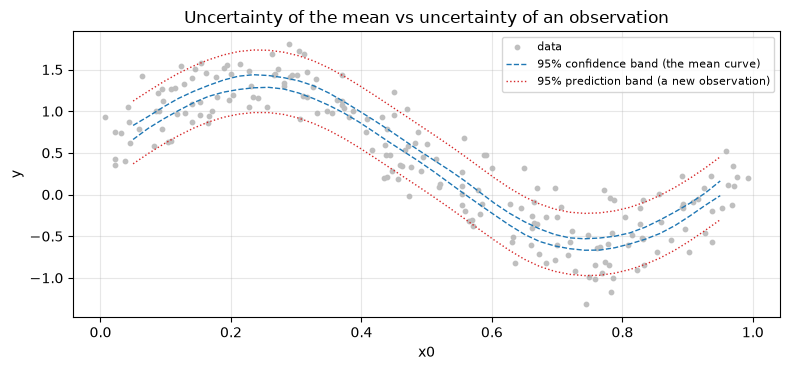

In [19]:
# --- confidence vs prediction intervals, by hand and from the library -------
grid = np.linspace(0.05, 0.95, 40)
grid2 = np.column_stack([grid, np.full_like(grid, X_inf[:, 1].mean())])
X_star = np.hstack([t.build_columns(grid2) for t in m_inf._terms] + [np.ones((grid2.shape[0], 1))])

mu = X_star @ m_inf.coef_
var_mean = np.sum((X_star @ Vp) * X_star, axis=1)
df_resid = max(n_inf - edf_total, 1.0)
t_q = stats.t.ppf(0.975, df_resid)

ci_hand = np.column_stack([mu - t_q * np.sqrt(var_mean), mu + t_q * np.sqrt(var_mean)])
var_pred = var_mean + scale
pi_hand = np.column_stack([mu - t_q * np.sqrt(var_pred), mu + t_q * np.sqrt(var_pred)])

ci = m_inf.confidence_intervals(grid2, width=0.95)
pi = m_inf.prediction_intervals(grid2, width=0.95)
print("max |CI hand - library| =", float(np.abs(ci_hand - ci).max()))
print("max |PI hand - library| =", float(np.abs(pi_hand - pi).max()))

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.scatter(X_inf[:, 0], y_inf, s=10, color="0.75", label="data")
ax.plot(grid, ci[:, 0], "C0--", lw=1)
ax.plot(grid, ci[:, 1], "C0--", lw=1, label="95% confidence band (the mean curve)")
ax.plot(grid, pi[:, 0], "C3:", lw=1)
ax.plot(grid, pi[:, 1], "C3:", lw=1, label="95% prediction band (a new observation)")
ax.set(xlabel="x0", ylabel="y", title="Uncertainty of the mean vs uncertainty of an observation")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

assert np.abs(ci_hand - ci).max() < 1e-9
assert np.abs(pi_hand - pi).max() < 1e-9
assert np.all(pi[:, 1] - pi[:, 0] > ci[:, 1] - ci[:, 0]), "prediction bands are always wider"

---
# Part VII. The workflow

The mathematics is now in place. In practice, fitting a Wood GAM is this loop:

1. **Look at the data** — ranges, units, obvious outliers, whether a covariate is
   cyclic or categorical.
2. **Write a first formula** — one `s()` per continuous covariate, `l()` for effects
   you believe are linear, `f()` for factors.
3. **Read the summary** — the parametric block, then the smooth block: EDF tells you
   how much structure each term found, `Ref.df` how much it was allowed to find,
   the F-test whether it found anything at all.
4. **Compare models** — drop collapsed terms, add `te()` for interactions, compare
   with REML/AIC/BIC *on the same data and the same fixed-effects structure*.
5. **Check the residuals** — `plot_diagnostics`; if a few observations dominate,
   refit with `weights=`.
6. **Report** — `predict`, the two interval types, `partial_dependence`,
   `plot_decomposition`.

The dataset: tool-life in an industrial cutting process with four inputs.

| variable | meaning | role in the simulation |
|---|---|---|
| `temp` | cutting temperature (°C) | quadratic optimum around 250 °C |
| `speed` | spindle speed (m/min) | sinusoidal, levelling off |
| `humid` | ambient humidity (%) | **interacts** with temperature |
| `shift` | shift identity (0, 1, 2) | small additive level effect |

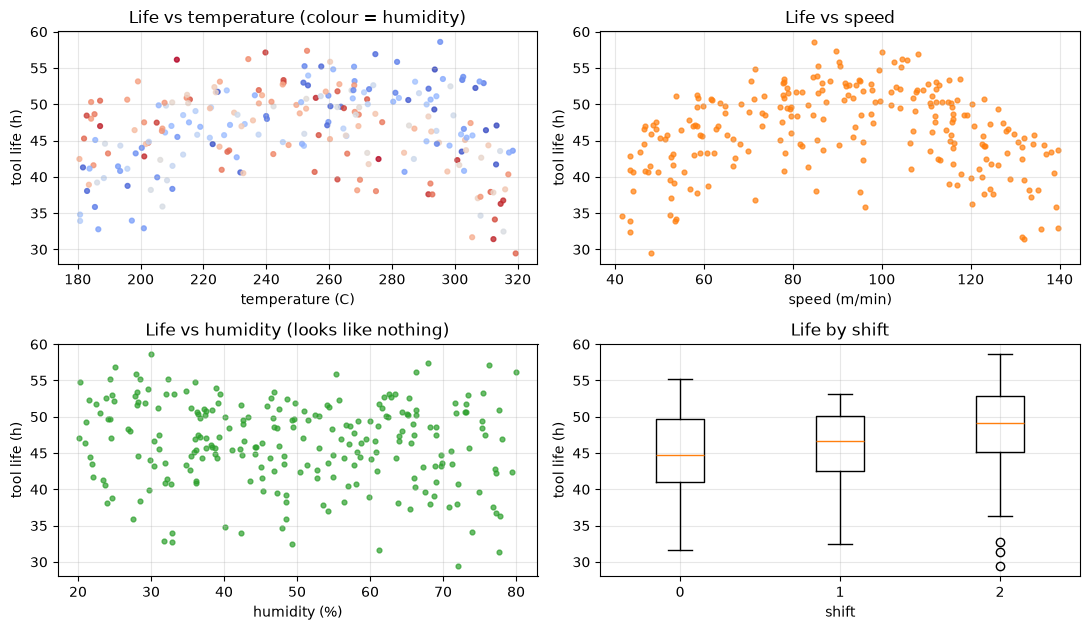

range: [180.5  41.5  20.2   0. ] to [319.4 139.7  79.9   2. ]


In [20]:
rng_wf = np.random.default_rng(7)
n_wf = 240
temp = rng_wf.uniform(180.0, 320.0, n_wf)
speed = rng_wf.uniform(40.0, 140.0, n_wf)
humid = rng_wf.uniform(20.0, 80.0, n_wf)
shift = rng_wf.choice([0.0, 1.0, 2.0], n_wf)

life = (40.0
        - 0.002 * (temp - 250.0) ** 2
        + 12.0 * np.sin((speed - 40.0) / 100.0 * np.pi)
        + 6.0 * np.cos(2 * np.pi * temp / 200.0) * (humid - 50.0) / 30.0
        + 1.5 * shift
        + rng_wf.normal(0.0, 1.6, n_wf))
X_wf = np.column_stack([temp, speed, humid, shift])
feature_names = ["temp", "speed", "humid", "shift"]

fig, axes = plt.subplots(2, 2, figsize=(11, 6.4))
axes[0, 0].scatter(temp, life, s=12, c=humid, cmap="coolwarm", alpha=0.8)
axes[0, 0].set(xlabel="temperature (C)", ylabel="tool life (h)", title="Life vs temperature (colour = humidity)")
axes[0, 1].scatter(speed, life, s=12, color="C1", alpha=0.7)
axes[0, 1].set(xlabel="speed (m/min)", ylabel="tool life (h)", title="Life vs speed")
axes[1, 0].scatter(humid, life, s=12, color="C2", alpha=0.7)
axes[1, 0].set(xlabel="humidity (%)", ylabel="tool life (h)", title="Life vs humidity (looks like nothing)")
axes[1, 1].boxplot([life[shift == s] for s in (0.0, 1.0, 2.0)], tick_labels=["0", "1", "2"])
axes[1, 1].set(xlabel="shift", ylabel="tool life (h)", title="Life by shift")
for ax in axes.ravel():
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("range:", np.round(X_wf.min(axis=0), 1), "to", np.round(X_wf.max(axis=0), 1))

In [21]:
# --- step 2/3: the first formula -------------------------------------------
formula_add = "s(0, k=12, bs='tp') + s(1, k=8, bs='tp') + s(2, k=8, bs='tp') + f(3)"
m_add = GAMCore(formula_add, backend="wood").fit(X_wf, life)
print(m_add.summary())

print("per-term EDF:", np.round(m_add.statistics_["edf_per_term"], 3))
print("per-term p  :", [f"{p:.3g}" for p in m_add.statistics_["p_values_per_term"]])
print("estimated sp:", np.round(m_add.statistics_["sp"], 4))
print("sigma^2 estimate:", round(m_add.statistics_["scale"], 3),
      " (the simulation used 1.6^2 = 2.56)")

# temperature and speed are strongly present; humidity is weak-but-not-nothing
assert m_add.statistics_["p_values_per_term"][0] < 1e-6
assert m_add.statistics_["p_values_per_term"][1] < 1e-6
assert m_add.statistics_["edf_per_term"][2] < 3.0


Family: gaussian 
Link function: identity 

Formula: s(0, k=12, bs='tp') + s(1, k=8, bs='tp') + s(2, k=8, bs='tp') + f(3)

Parametric coefficients:
            Estimate Std. Error t value Pr(>|t|)
(Intercept)    44.6777     0.3626 123.225        0

Approximate significance of smooth terms:
        edf Ref.df      F p-value
s(0)      5.46     11 40.137 1.11e-16
s(1)      4.72      7 59.748 1.11e-16
s(2)      1.89      7  2.147    0.122

R-sq.(adj) = 0.7019   Deviance explained = 71.9%
REML =   625.9450  Scale est. = 9.8542   n = 240

per-term EDF: [5.456 4.719 1.894 2.   ]
per-term p  : ['1.11e-16', '1.11e-16', '0.122', '9.04e-10']
estimated sp: [0.049  0.0874 4.0192]
sigma^2 estimate: 9.854  (the simulation used 1.6^2 = 2.56)


Three things to notice in that summary — all of them normal, and all of them
things a practitioner must be able to read:

1. `s(temp)` and `s(speed)` are overwhelming (p $< 10^{-16}$), with EDF 5.5 and 4.7
   out of 11 and 7 available coefficients. Real structure, modest complexity.
2. `s(humid)` came in at EDF $\approx 1.9$ with p $\approx 0.12$: *not significant*,
   but not exactly zero either. The additive model is trying to soak up an
   interaction it cannot represent.
3. `f(shift)` gets a test row? No — *look at the table again*: factor terms do not
   get a summary row in the Wood backend, because the row builder only walks
   smooth and linear terms. Their coefficients are in `coef_` (and in
   `edf_per_term`), and their levels are what `f()` encodes.

And the scale estimate is $\hat\sigma^2 \approx 9.9$ against a true noise variance
of $2.56$ — a factor of four. Nothing is "wrong": $\hat\sigma^2$ absorbs
everything the additive formula failed to model, which here is the
temperature-humidity interaction. This is the model-selection signal.

In [22]:
# --- step 4: compare models on the same data -------------------------------
candidates = {
    "additive": formula_add,
    "additive minus humid": "s(0, k=12, bs='tp') + s(1, k=8, bs='tp') + f(3)",
    "te(temp, humid)": "te(0, 2, k=6, bs='cr') + s(1, k=8, bs='tp') + f(3)",
    "te + marginals": "s(0, k=12, bs='tp') + s(2, k=8, bs='tp') + te(0, 2, k=5, bs='cr') + s(1, k=8, bs='tp') + f(3)",
}
fits = {name: GAMCore(form, backend="wood").fit(X_wf, life) for name, form in candidates.items()}

print(f"{'model':>22} {'EDF':>7} {'REML':>10} {'AIC':>10} {'BIC':>10} {'R2adj':>7} {'dev.exp':>8}")
for name, m in fits.items():
    print(f"{name:>22} {m.statistics_['edof']:7.2f} {m.statistics_['score']:10.2f} "
          f"{m.aic():10.2f} {m.bic():10.2f} {m.statistics_['r_sq_adj']:7.3f} "
          f"{m.statistics_['deviance_explained']:8.3f}")

print("\nper-term EDF of the interaction models:")
for name in ("te(temp, humid)", "te + marginals"):
    print(f"  {name:>22}: {np.round(fits[name].statistics_['edf_per_term'], 3)}")
te_model = fits["te(temp, humid)"]
f_start, f_end = te_model._coef_slices[-1]          # the f(shift) term
print("f(shift) coefficients (f() has no summary row):",
      np.round(te_model.coef_[f_start:f_end], 3),
      " intercept:", round(float(te_model.coef_[-1]), 3))

# the interaction model wins decisively, and the marginal terms collapse to ~1 EDF
assert fits["te(temp, humid)"].aic() < fits["additive"].aic() - 50
assert fits["te + marginals"].statistics_["edf_per_term"][0] < 1.5
assert min(fits["te + marginals"].statistics_["p_values_per_term"][:2]) > 0.5
assert abs(fits["te(temp, humid)"].statistics_["scale"] - 2.56) < 1.0

                 model     EDF       REML        AIC        BIC   R2adj  dev.exp


              additive   15.07     625.95    1247.26    1303.19   0.702    0.719
  additive minus humid   13.28     626.69    1248.23    1297.94   0.698    0.714
       te(temp, humid)   20.68     463.03     909.45     984.93   0.929    0.935
        te + marginals   19.91     435.88     907.52     980.29   0.929    0.935

per-term EDF of the interaction models:
         te(temp, humid): [11.751  5.933  2.   ]
          te + marginals: [0.974 0.979 9.003 5.948 2.   ]
f(shift) coefficients (f() has no summary row): [1.784 3.342]  intercept: 44.562


That table is the whole model-selection conversation in four rows:

* dropping `s(humid)` from the additive model makes REML and AIC *worse* — the weak
  term was still paying for itself, just barely;
* adding `te(temp, humid)` cuts the REML score by ~160 points, the residual
  variance from 9.85 to 2.36 (the true value is 2.56), and deviance explained from
  0.72 to 0.93. **The interaction was the missing structure.**
* adding the marginal `s(temp)` and `s(humid)` on top of the tensor product is
  nearly free in AIC (a 2-point difference is noise) but informative: both
  marginals collapse to EDF $\approx 1$ with p $\approx 1$ — the tensor products
  already contain the main effects. Watching a term collapse to EDF 1 is a more
  reliable signal than reading a p-value of 1.

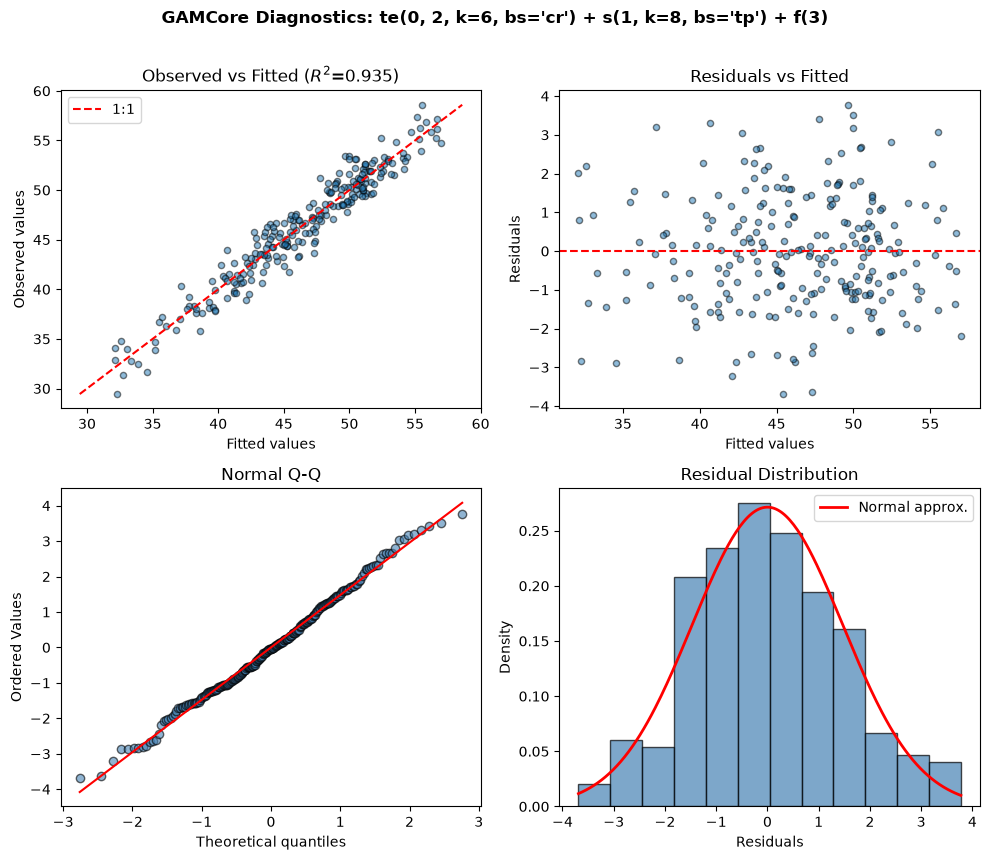

residual sd: 1.47  (true noise sd = 1.6)
largest |standardised residual|: 2.57


In [23]:
# --- step 5: are the residuals well behaved? --------------------------------
fig, axes = fits["te(temp, humid)"].plot_diagnostics(X_wf, life)
plt.show()

resid = life - fits["te(temp, humid)"].predict(X_wf)
print("residual sd:", round(float(np.std(resid, ddof=1)), 3),
      " (true noise sd = 1.6)")
print("largest |standardised residual|:",
      round(float(np.max(np.abs(resid - np.mean(resid)) / np.std(resid, ddof=1))), 2))

### Outliers and `weights=`

Diagnostics on this simulated dataset are tame. Real data has spikes, so it is
worth knowing the tooling: `fit(..., weights=w)` accepts observation weights, and
the standard recipe is to fit once, compute MAD-scaled residuals, and down-weight
anything beyond Huber's 1.345 cut.

Two rules of thumb that the next cell demonstrates on a *deliberately dirty*
1-D dataset:

* the weighted fit should reproduce, as closely as possible, what you would get by
  deleting the outliers and refitting;
* never compare AIC between a weighted and an unweighted fit — the weighted
  log-likelihood contains $\tfrac12\sum\log w_i$, which is not a model-fit quantity.

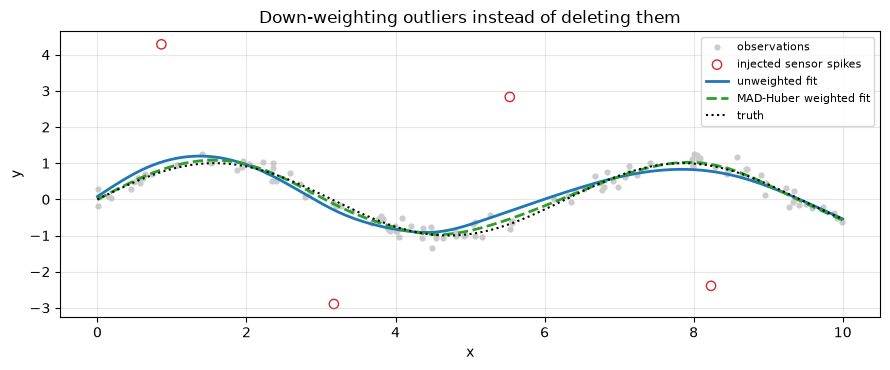

MAE against the truth, clean points:
  unweighted          0.1807
  MAD-Huber weighted  0.1232
  outliers deleted    0.1210
residual sd estimate  : 0.619 0.258
weights at the spikes : [0.104 0.131 0.108 0.107]   (n down-weighted: 16 of 120 )


In [24]:
rng_out = np.random.default_rng(5)
n_out = 120
x_out = np.sort(rng_out.uniform(0.0, 10.0, n_out))
truth_out = np.sin(x_out)
y_out = truth_out + rng_out.normal(0.0, 0.15, n_out)
spikes = np.array([12, 34, 67, 95])
y_out[spikes] += np.array([3.4, -3.1, 3.6, -3.3])

plain = GAM(k=14, bs="cr", backend="wood").fit(x_out, y_out)
resid_plain = y_out - plain.predict(x_out)
mad = 1.4826 * np.median(np.abs(resid_plain - np.median(resid_plain)))
u = np.abs(resid_plain) / mad
w = np.where(u <= 1.345, 1.0, 1.345 / u)
robust = GAM(k=14, bs="cr", backend="wood").fit(x_out, y_out, weights=w)

clean = np.setdiff1d(np.arange(n_out), spikes)
drop = GAM(k=14, bs="cr", backend="wood").fit(x_out[clean], y_out[clean])

xg = np.linspace(0.0, 10.0, 400)
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.scatter(x_out[clean], y_out[clean], s=12, color="0.8", label="observations")
ax.scatter(x_out[spikes], y_out[spikes], s=45, facecolors="none", edgecolors="C3",
           label="injected sensor spikes")
ax.plot(xg, plain.predict(xg), "C0-", lw=2, label="unweighted fit")
ax.plot(xg, robust.predict(xg), "C2--", lw=2, label="MAD-Huber weighted fit")
ax.plot(xg, np.sin(xg), "k:", lw=1.5, label="truth")
ax.set(xlabel="x", ylabel="y", title="Down-weighting outliers instead of deleting them")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

mae = lambda m: float(np.mean(np.abs((y_out - m.predict(x_out))[clean])))
print("MAE against the truth, clean points:")
print(f"  unweighted          {mae(plain):.4f}")
print(f"  MAD-Huber weighted  {mae(robust):.4f}")
print(f"  outliers deleted    {mae(drop):.4f}")
print("residual sd estimate  :",
      round(float(np.sqrt(plain.statistics_['scale'])), 3),
      round(float(np.sqrt(robust.statistics_['scale'])), 3))
print("weights at the spikes :", np.round(w[spikes], 3),
      "  (n down-weighted:", int((w < 1).sum()), "of", n_out, ")")

assert w[spikes].max() < 0.2
assert mae(robust) < mae(plain)
assert robust.statistics_["scale"] < plain.statistics_["scale"]

### How much basis dimension do you need?

Two questions that look similar and are not:

* **How many knots?** With REML choosing $\lambda$, the answer is "enough that the
  truth is representable". If `k` is too small the fit is biased (and EDF runs into
  the ceiling); if `k` is larger than needed, the penalty simply buys back the
  extra flexibility and the EDF saturates below the ceiling. `k` is a *sufficient
  dimension*, not a complexity knob — $\lambda$ is the complexity knob.
* **Which basis?** Almost irrelevant for centred, interior data: `cr`, `ps`, `bs`
  and `tp` are different ways of writing similar function spaces. It matters for
  boundaries (linear extrapolation for `cr`/`ps`, natural vs periodic), for
  smooths on a circle (`cc`), and when you want a term to be able to switch itself
  off (`ts`/`cs`).

In [25]:
# --- k sweep for the temperature term ---------------------------------------
print(f"{'k':>4} {'EDF(temp)':>10} {'sp(temp)':>12} {'REML':>10}")
k_results = []
for kk in (6, 8, 10, 14, 18):
    m = GAMCore(f"s(0, k={kk}, bs='tp') + s(1, k=8, bs='tp') + f(3)", backend="wood").fit(X_wf, life)
    k_results.append((kk, m.statistics_["edf_per_term"][0], m.statistics_["sp"][0], m.statistics_["score"]))
    print(f"{kk:4d} {m.statistics_['edf_per_term'][0]:10.3f} "
          f"{m.statistics_['sp'][0]:12.4g} {m.statistics_['score']:10.3f}")

edfs_k = [row[1] for row in k_results]
remls_k = [row[3] for row in k_results]
print(f"\nEDF range across k: {min(edfs_k):.2f} .. {max(edfs_k):.2f}"
      f"   REML spread: {max(remls_k) - min(remls_k):.2f}")

assert edfs_k[-1] < k_results[-1][0] - 3, "even k=18 must not saturate: the penalty is doing the work"
assert max(remls_k) - min(remls_k) < 3.0, "the fit must be insensitive to k once k is large enough"

# --- basis comparison -------------------------------------------------------
print(f"\n{'basis':>6} {'EDF(temp)':>10} {'sp(temp)':>10} {'REML':>10} {'AIC':>10}")
for bs_code in ("tp", "cr", "ps", "ts"):
    m = GAMCore(f"s(0, k=10, bs='{bs_code}') + s(1, k=8, bs='tp') + f(3)", backend="wood").fit(X_wf, life)
    print(f"{bs_code:>6} {m.statistics_['edf_per_term'][0]:10.3f} {m.statistics_['sp'][0]:10.4g} "
          f"{m.statistics_['score']:10.2f} {m.aic():10.2f}")

   k  EDF(temp)     sp(temp)       REML


   6      4.437      0.05097    626.757
   8      5.215      0.05837    626.484
  10      5.449      0.06084    626.638
  14      5.595      0.04735    626.700
  18      5.643        0.103    626.713

EDF range across k: 4.44 .. 5.64   REML spread: 0.27

 basis  EDF(temp)   sp(temp)       REML        AIC
    tp      5.449    0.06084     626.64    1248.03
    cr      5.414      43.25     625.37    1247.91
    ps      4.883      12.96     624.97    1247.47
    ts      5.139     0.0801     631.26    1248.20


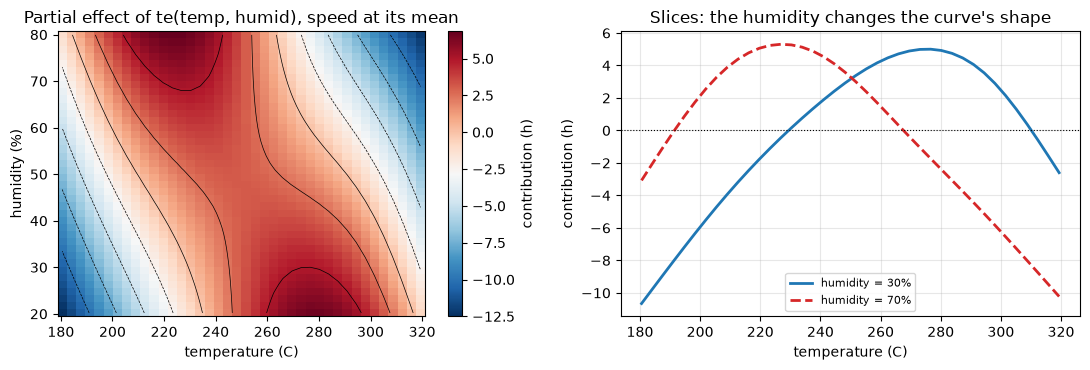

te term: EDF = 11.75 of 35 coefficients
sample mean of the te partial effect: 6.217248937900876e-16


In [26]:
# --- the interaction surface, and how to read a te() term ------------------
best = fits["te(temp, humid)"]
grid_t = np.linspace(temp.min(), temp.max(), 40)
grid_h = np.linspace(humid.min(), humid.max(), 40)
GT, GH = np.meshgrid(grid_t, grid_h, indexing="ij")
pts = np.column_stack([GT.ravel(), np.full(GT.size, speed.mean()), GH.ravel(), np.zeros(GT.size)])
surface = best.partial_dependence(0, pts).reshape(GT.shape)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
im = axes[0].pcolormesh(GT, GH, surface, cmap="RdBu_r", shading="auto")
axes[0].contour(GT, GH, surface, colors="k", linewidths=0.5, levels=8)
axes[0].set(xlabel="temperature (C)", ylabel="humidity (%)", title="Partial effect of te(temp, humid), speed at its mean")
plt.colorbar(im, ax=axes[0], label="contribution (h)")

axes[1].plot(grid_t, best.partial_dependence(0, np.column_stack([grid_t, np.full_like(grid_t, speed.mean()), np.full_like(grid_t, 30.0), np.zeros_like(grid_t)])),
             "C0-", lw=2, label="humidity = 30%")
axes[1].plot(grid_t, best.partial_dependence(0, np.column_stack([grid_t, np.full_like(grid_t, speed.mean()), np.full_like(grid_t, 70.0), np.zeros_like(grid_t)])),
             "C3--", lw=2, label="humidity = 70%")
axes[1].axhline(0, color="k", lw=0.8, ls=":")
axes[1].set(xlabel="temperature (C)", ylabel="contribution (h)",
            title="Slices: the humidity changes the curve's shape")
axes[1].legend(fontsize=8)
axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("te term: EDF =", round(best.statistics_["edf_per_term"][0], 2),
      "of", best._terms[0].n_coefs, "coefficients")
print("sample mean of the te partial effect:", float(np.mean(best.partial_dependence(0, X_wf))))
assert abs(float(np.mean(best.partial_dependence(0, X_wf)))) < 1e-9

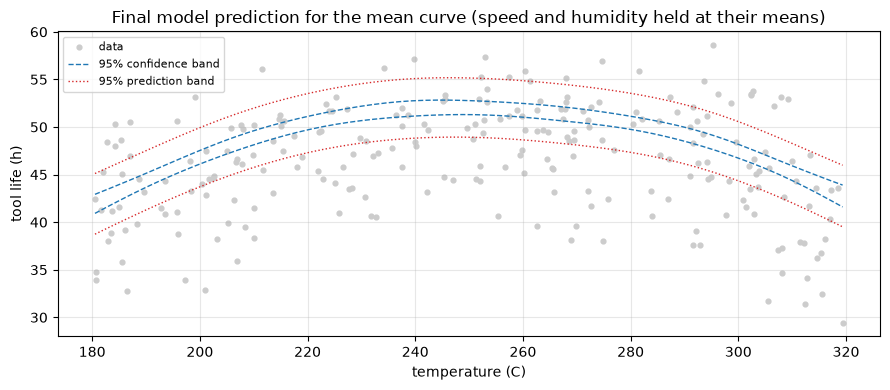

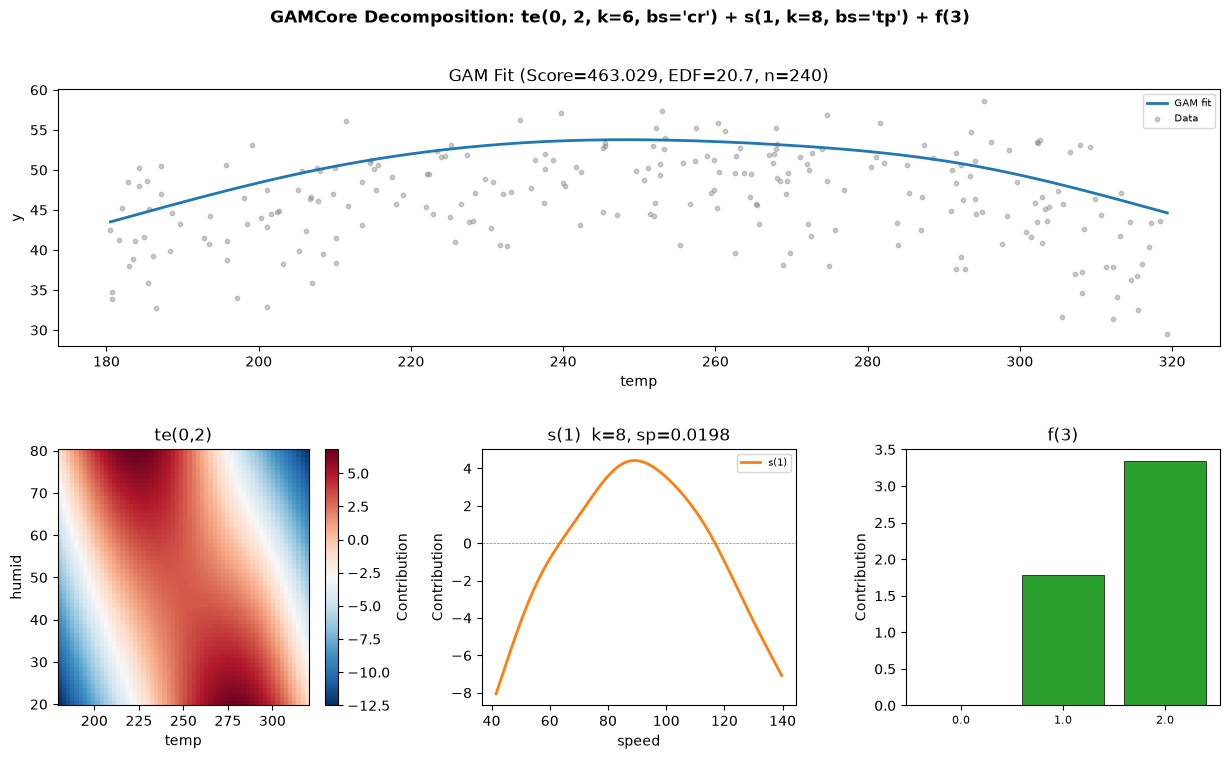

deviance explained: 0.9346
R^2 adjusted      : 0.9287
AIC / BIC         : 909.45 / 984.93
estimated sp      : [  0.3474 216.6772   0.0198]
predicted life quartiles: [32.11 42.79 46.92 50.56 56.99] h


In [27]:
# --- step 6: the report -----------------------------------------------------
final = fits["te(temp, humid)"]
slice_temp = np.linspace(temp.min(), temp.max(), 60)
report_pts = np.column_stack([slice_temp, np.full_like(slice_temp, speed.mean()),
                              np.full_like(slice_temp, humid.mean()), np.zeros_like(slice_temp)])
ci_rep = final.confidence_intervals(report_pts, width=0.95)
pi_rep = final.prediction_intervals(report_pts, width=0.95)

fig, ax = plt.subplots(figsize=(9, 4))
ax.scatter(temp, life, s=12, color="0.8", label="data")
ax.plot(slice_temp, ci_rep[:, 0], "C0--", lw=1)
ax.plot(slice_temp, ci_rep[:, 1], "C0--", lw=1, label="95% confidence band")
ax.plot(slice_temp, pi_rep[:, 0], "C3:", lw=1)
ax.plot(slice_temp, pi_rep[:, 1], "C3:", lw=1, label="95% prediction band")
ax.set(xlabel="temperature (C)", ylabel="tool life (h)",
       title="Final model prediction for the mean curve (speed and humidity held at their means)")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

fig, axes = final.plot_decomposition(X_wf, life, feature_names=feature_names)
plt.show()

print("deviance explained:", round(final.statistics_["deviance_explained"], 4))
print("R^2 adjusted      :", round(final.statistics_["r_sq_adj"], 4))
print("AIC / BIC         :", round(final.aic(), 2), "/", round(final.bic(), 2))
print("estimated sp      :", np.round(final.statistics_["sp"], 4))

edges = np.quantile(final.predict(X_wf), [0.0, 0.25, 0.5, 0.75, 1.0])
print("predicted life quartiles:", np.round(edges, 2), "h")
assert final.aic() < m_add.aic()

---
# Cheat sheet

## API map for the Wood backend

| what you want | call |
|---|---|
| fit one smooth | `LinGAM(k=10, bs='cr').fit(x, y)` (alias `GAM`) |
| fit a formula | `GAMCore("s(0, k=10) + te(0,1, k=5) + f(2) + l(3)").fit(X, y)` |
| automatic `lambda` | the default (`method='REML'`); `method='GCV.Cp'` for GCV |
| pin a `lambda` | `s(0, k=10, sp=4.0)` or `LinGAM(..., sp=4.0)` |
| search over `k` | `model.gridsearch(X, y, n_splines_grids=[np.arange(6, 13, 2)] * 2)` |
| read the table | `model.summary()` |
| machine-readable stats | `model.statistics_` (`edof`, `edf_per_term`, `sp`, `Vp`, `Ve`, `f_stat_per_term`, `p_values_per_term`, `scale`, `score`, ...) |
| effects | `model.partial_dependence(j, X)`, `model.plot_decomposition(X, y)` |
| predictions | `model.predict(x)`, `confidence_intervals`, `prediction_intervals` |
| model comparison | `model.aic()`, `model.bic()`, `model.deviance_explained()`, `statistics_['score']` |
| diagnostics | `fig, axes = model.plot_diagnostics(X, y)` |

## Which basis when

| situation | choice |
|---|---|
| default 1-D smooth | `tp` (or `cr` when you want speed and linear extrapolation) |
| term that must be able to disappear | `ts` / `cs` (shrinkage) |
| cyclic covariate | `cc` / `cp` with `knots=(lo, hi)` |
| many levels of a factor | `s(j, bs='re')` (random effect / ridge) |
| fixed factor with few levels | `f(j)` (unpenalised, no summary row) |
| interaction | `te(i, j, k=..., bs='cr')` |
| monotonic / convex shapes | not available here — use `backend='eilers'` |

## Traps worth remembering

1. `sp` is on the **rescaled** penalty scale (`S.scale`), so the number is not
   portable between hand-built and library-built models unless you rescale the same way.
2. Minimum EDF of a `cr`/`tp`/`ps` term is **1**, not 0: a straight line is free.
   Only the shrinkage bases (`ts`, `cs`, `re`) can collapse a term to 0.
3. p-values for terms with EDF $\lesssim 1.5$ are unreliable (Wood 2013's own
   caveat). A term at EDF 1 is "a straight line you did not ask for".
4. `AIC`/`BIC`/`REML` comparisons require the *same* response and the *same*
   weighting; weighted and unweighted log-likelihoods are not comparable.
5. `f()` terms and the `re` basis print no summary row / a misleading `Ref.df`
   (`k-1`). Read their coefficients and EDF from `coef_` and `statistics_`.
6. A `tp` smooth needs at least `k` distinct covariate values — `s(3)` on a
   3-level factor raises. Use `f()` or `bs='re'` instead.
7. Confidence intervals treat $\hat\lambda$ as known, and extrapolation
   confidence grows very fast. Both are standard, neither is a substitute for
   checking the residuals.

## Where to read more

* `docs/math/wood.rst` in the magli repository — the full derivations behind
  Parts I–VI.
* S. N. Wood (2003), *Thin plate regression splines*, JRSS-B.
* S. N. Wood (2011), *Fast stable REML and ML estimation of semiparametric
  generalized linear models*, JRSS-B.
* S. N. Wood (2013), *On p-values for smooth components of an extended nonlinear
  model*, Biometrika.
* S. N. Wood (2017), *Generalized Additive Models: An Introduction with R* (2nd
  ed.), CRC Press — especially chapter 5 (basis and penalty) and chapter 6
  (inference).

In [28]:
# --- closing invariant audit ------------------------------------------------
# Everything below was established earlier in the notebook; this cell recomputes
# the headline numbers from scratch so that the notebook has a single pass/fail hook.
checks = {}

# 1. absorption removes the constant direction from the basis
checks["absorbed column sums ~ 0"] = float(np.abs(X_t.sum(axis=0)).max())

# 2. hand-built design reproduces the public class exactly
checks["|beta_hand - engine|"] = float(np.abs(fit_free["coef"] - model.coef_).max())

# 3. the REML criterion is minimised at the fitted smoothing parameter
rho_hat_check = float(np.log(model.lam))
checks["|grad REML at rho_hat|"] = abs(float(reml_grad_analytic(rho_hat_check, X_design, y, S_design)))

# 4. EDF bookkeeping is consistent
checks["|sum(EDF per coef) - EDF|"] = abs(edof_coef.sum() - model.statistics_["edof"])

# 5. the constraint survives each fit
checks["|mean partial effect|"] = abs(float(np.mean(m_cent.partial_dependence(0, X_cent))))

# 6. interval algebra matches the library
checks["|CI hand - CI library|"] = float(np.abs(ci_hand - ci).max())

print(f"{'check':>28} {'value':>14}")
for name, value in checks.items():
    print(f"{name:>28} {value:14.3e}")

assert all(v < 1e-6 for v in checks.values())
print("\nAll invariant checks passed. The markdown and the code agree.")

                       check          value
    absorbed column sums ~ 0      1.529e-14
        |beta_hand - engine|      0.000e+00
      |grad REML at rho_hat|      8.438e-15
   |sum(EDF per coef) - EDF|      0.000e+00
       |mean partial effect|      0.000e+00
      |CI hand - CI library|      0.000e+00

All invariant checks passed. The markdown and the code agree.
